![image.png](https://i.imgur.com/a3uAqnb.png)

# Transformer from Scratch for Text Summarization

In this  assignment, you will implement a **complete Transformer architecture from scratch** for text summarization using the BBC News dataset. This project will deepen your understanding of attention mechanisms, positional encoding, and sequence-to-sequence modeling.

## 🎯 Project Overview
- **Task**: Automatic text summarization of BBC news articles
- **Architecture**: Full Transformer (Encoder-Decoder) implementation from scratch
- **Dataset**: BBC News Summary Dataset
- **Goal**: Build and train a production-ready summarization model

## 📚 Learning Objectives
By completing this assignment, you will:
- Understand and implement multi-head self-attention mechanisms
- Build positional encoding for sequence modeling
- Implement complete Encoder-Decoder Transformer architecture
- Learn advanced training techniques (label smoothing, gradient clipping, learning rate scheduling)
- Evaluate summarization quality using ROUGE metrics
- Master sequence generation and beam search techniques

## 1️⃣ Dataset Download and Initial Exploration

**Task**: Download the BBC News dataset and explore its structure for summarization.

**Requirements**:
- Download BBC News Summary dataset from Kaggle
- Explore the directory structure (articles vs summaries)
- Analyze article and summary length distributions
- Understand the data format and categories

In [ ]:
import os
import re
import random
from pathlib import Path
from collections import Counter

import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# torch seeding if available later in the notebook
try:
    import torch
except Exception:
    torch = None

# Reproducibility
SEED = 42
def set_seed(seed: int = 42) -> None:
    """Set seeds for reproducibility across Python, NumPy, and (optionally) PyTorch."""
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    if torch is not None:
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        # Ensure deterministic behavior for cuDNN
        if hasattr(torch.backends, "cudnn"):
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False

set_seed(SEED)

# Dataset resolution
def _resolve_bbc_path() -> Path:
    """
    Resolve the BBC News Summary dataset path.
    First tries kagglehub; if unavailable, uses env var BBC_NEWS_SUMMARY_DIR.
    """
    try:
        path = kagglehub.dataset_download("pariza/bbc-news-summary")
        return Path(path)
    except Exception as e:
        env = os.getenv("BBC_NEWS_SUMMARY_DIR")
        if env:
            p = Path(env)
            if p.exists():
                return p
        raise RuntimeError(
            "Could not download dataset via kagglehub and no BBC_NEWS_SUMMARY_DIR is set."
        ) from e

ROOT = _resolve_bbc_path()

# Helpers
CATEGORIES = ["business", "entertainment", "politics", "sport", "tech"]

def _robust_read_text(p: Path) -> str:
    """Read text with common encodings; fall back to bytes decode with 'ignore'."""
    for enc in ("utf-8", "latin-1"):
        try:
            return p.read_text(encoding=enc, errors="ignore")
        except Exception:
            continue
    return p.read_bytes().decode("utf-8", errors="ignore")

def _has_all_categories(p: Path) -> bool:
    """Check if path contains subdirectories for all expected categories (case-insensitive)."""
    try:
        subs = {d.name.lower() for d in p.iterdir() if d.is_dir()}
    except Exception:
        return False
    return all(c in subs for c in CATEGORIES)

def _list_category_files(root: Path, category: str):
    """List all .txt files under a category directory (case-insensitive), recursively."""
    d = root / category
    if not d.exists():
        # Try case-insensitive match among immediate children
        matches = [x for x in root.iterdir() if x.is_dir() and x.name.lower() == category.lower()]
        d = matches[0] if matches else None
    if d is None or not d.exists():
        return []
    return sorted([f for f in d.rglob("*.txt") if f.is_file()])

def _find_roots(root: Path):
    """
    Find the 'articles' and 'summaries' roots by scanning for directories
    that each contain the five BBC categories. Prefer one with 'summary' in the path.
    Returns: (articles_root, summaries_root)
    """
    candidates = []
    for dirpath, _, _ in os.walk(root):
        p = Path(dirpath)
        if _has_all_categories(p):
            candidates.append(p)

    # Prefer directory with 'summary' in its name for summaries; another for articles
    summaries = next((p for p in candidates if "summary" in str(p).lower()), None)
    articles = next((p for p in candidates if p != summaries), None)

    if summaries is None or articles is None:
        if len(candidates) >= 2:
            # Heuristic: pick one that looks like 'news articles'
            articles = next((p for p in candidates if "article" in str(p).lower()), candidates[0])
            summaries = next((p for p in candidates if p != articles), candidates[1])
        else:
            raise RuntimeError("Could not detect Articles/Summaries roots automatically.")
    return articles, summaries

def _word_count(text: str) -> int:
    """Approximate word count using token pattern \\b\\w+\\b."""
    return len(re.findall(r"\b\w+\b", text))

def explore_dataset_structure(root: Path):
    """
    Explore dataset structure and return roots and counts by category.
    Returns dict with:
      - articles_root / summaries_root (Path)
      - categories (list)
      - article_counts / summary_counts (dict[str, int])
    """
    articles_root, summaries_root = _find_roots(root)
    article_counts = {c: len(_list_category_files(articles_root, c)) for c in CATEGORIES}
    summary_counts = {c: len(_list_category_files(summaries_root, c)) for c in CATEGORIES}
    return {
        "articles_root": articles_root,
        "summaries_root": summaries_root,
        "categories": CATEGORIES,
        "article_counts": article_counts,
        "summary_counts": summary_counts,
    }

# Explore dataset structure and display basic statistics

info = explore_dataset_structure(ROOT)
total_articles = sum(info["article_counts"].values())

# Load and display sample article and summary to understand data format
sample_cat = next((c for c in info["categories"] if info["article_counts"].get(c, 0) > 0), None)
if sample_cat is None:
    raise RuntimeError("No articles found.")

article_files = _list_category_files(info["articles_root"], sample_cat)
summary_files = _list_category_files(info["summaries_root"], sample_cat)

# Choose middle file for determinism
idx = len(article_files) // 2 if article_files else 0
sample_article = article_files[idx]

# Try to match summary by stem; else pick middle summary
sample_summary = None
if summary_files:
    same = [s for s in summary_files if s.stem.lower() == sample_article.stem.lower()]
    sample_summary = same[0] if same else summary_files[min(idx, len(summary_files) - 1)]

article_text = _robust_read_text(sample_article)
summary_text = _robust_read_text(sample_summary) if sample_summary else ""

# REQUIRED OUTPUT (exactly these three lines)
print(f"Total articles loaded: {total_articles}")
print(f"Sample article length: {_word_count(article_text)} words")
print(f"Sample summary length: {_word_count(summary_text)} words")


In [ ]:
import kagglehub
import os
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from collections import Counter
import re

# Download the BBC News Summary dataset
path = kagglehub.dataset_download("pariza/bbc-news-summary")
ROOT = Path(path)

# Helpers
CATEGORIES = ["business", "entertainment", "politics", "sport", "tech"]

def _robust_read_text(p: Path) -> str:
    for enc in ("utf-8", "latin-1"):
        try:
            return p.read_text(encoding=enc, errors="ignore")
        except Exception:
            continue
    return p.read_bytes().decode("utf-8", errors="ignore")

def _has_all_categories(p: Path) -> bool:
    try:
        subs = {d.name.lower() for d in p.iterdir() if d.is_dir()}
    except Exception:
        return False
    return all(c in subs for c in CATEGORIES)

def _list_category_files(root: Path, category: str):
    d = root / category
    if not d.exists():
        # case variants
        matches = [x for x in root.iterdir() if x.is_dir() and x.name.lower() == category]
        d = matches[0] if matches else None
    if d is None or not d.exists():
        return []
    return sorted([f for f in d.rglob("*.txt") if f.is_file()])

def _find_roots(root: Path):
    # search for two dirs that each contain the five BBC categories
    candidates = []
    for dirpath, dirnames, filenames in os.walk(root):
        p = Path(dirpath)
        if _has_all_categories(p):
            candidates.append(p)
    # prefer one with 'summary' in name as summaries, another as articles
    summaries = next((p for p in candidates if "summary" in str(p).lower()), None)
    articles = next((p for p in candidates if p != summaries), None)
    if summaries is None or articles is None:
        # fallbacks: take first two if present
        if len(candidates) >= 2:
            articles, summaries = candidates[0], candidates[1]
        else:
            raise RuntimeError("Could not detect Articles/Summaries roots automatically.")
    return articles, summaries

def _word_count(text: str) -> int:
    return len(re.findall(r"\b\w+\b", text))

# Implement function to explore dataset structure
def explore_dataset_structure(root: Path):
    articles_root, summaries_root = _find_roots(root)

    # Navigate to articles and summaries directories
    #Count files in each category
    article_counts = {c: len(_list_category_files(articles_root, c)) for c in CATEGORIES}
    summary_counts = {c: len(_list_category_files(summaries_root, c)) for c in CATEGORIES}

    # Return directory paths and category lists
    return {
        "articles_root": articles_root,
        "summaries_root": summaries_root,
        "categories": CATEGORIES,
        "article_counts": article_counts,
        "summary_counts": summary_counts,
    }

# Explore dataset structure and display basic statistics
info = explore_dataset_structure(ROOT)
total_articles = sum(info["article_counts"].values())

# Load and display sample article and summary to understand data format
# pick a category that has at least one article
sample_cat = next((c for c in info["categories"] if info["article_counts"].get(c, 0) > 0), None)
if sample_cat is None:
    raise RuntimeError("No articles found.")

article_files = _list_category_files(info["articles_root"], sample_cat)
summary_files = _list_category_files(info["summaries_root"], sample_cat)

# choose middle file for determinism
idx = len(article_files) // 2 if article_files else 0
sample_article = article_files[idx]

# try to match summary by stem; else middle summary
sample_summary = None
if summary_files:
    same = [s for s in summary_files if s.stem.lower() == sample_article.stem.lower()]
    sample_summary = same[0] if same else summary_files[min(idx, len(summary_files)-1)]

article_text = _robust_read_text(sample_article)
summary_text = _robust_read_text(sample_summary) if sample_summary else ""

# REQUIRED OUTPUT (exactly these three lines)
print(f"Total articles loaded: {total_articles}")
print(f"Sample article length: {_word_count(article_text)} words")
print(f"Sample summary length: {_word_count(summary_text)} words")


Total articles loaded: 2225
Sample article length: 217 words
Sample summary length: 107 words


## 2️⃣ Import Required Libraries

**Task**: Import all necessary libraries for Transformer implementation and training.

**Requirements**:
- Import PyTorch and neural network modules
- Import text processing utilities
- Import evaluation metrics (ROUGE)
- Set up visualization libraries

In [ ]:
!pip install torch torchvision torchtext rouge-score matplotlib seaborn


  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 80.3 MB/s eta 0:00:00
  Created wheel for rouge-score: filename=rouge_score-0.1.2-py3-none-any.whl size=24934 sha256=624fb1925d5d97843da277944808d68144b233ef0b178a90fcd55b7d9713eb25
  Stored in directory: /root/.cache/pip/wheels/85/9d/af/01feefbe7d55ef5468796f0c68225b6788e85d9d0a281e7a70
Successfully built rouge-score


In [ ]:
# PyTorch and neural network modules
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# TODO: Import data processing and utility libraries
import numpy as np
import pandas as pd


## 3️⃣ Data Loading and Text Preprocessing

**Task**: Create a comprehensive data loading pipeline with text cleaning.

**Requirements**:
- Implement BBCNewsDataset class for loading articles and summaries
- Create robust text cleaning function
- Load all categories (politics, entertainment, sport, tech, business)
- Handle encoding errors and empty files
- Display dataset statistics

In [ ]:
from pathlib import Path
import os
import re
import random
from typing import Dict, List, Tuple, Optional

import pandas as pd
import numpy as np

CATEGORIES = ["politics", "entertainment", "sport", "tech", "business"]

class BBCNewsDataset:
    """
    Comprehensive dataset loader for the BBC News Summary dataset.

    Responsibilities:
    - Discover article and summary roots automatically
    - Load paired article/summary files per category
    - Robust text reading with encoding fallbacks
    - Deterministic pairing by filename stem
    - Text cleaning & basic normalization
    - Optional length filtering and deduplication
    """

    def __init__(self, base_path, seed: int = 42):
        self.rng = random.Random(seed)
        self.base_path = Path(base_path)
        self.articles_root, self.summaries_root = self._find_roots(self.base_path)

    def _has_all_categories(self, p: Path) -> bool:
        try:
            subs = {d.name.lower() for d in p.iterdir() if d.is_dir()}
        except Exception:
            return False
        return all(c in subs for c in CATEGORIES)

    def _find_roots(self, root: Path) -> Tuple[Path, Path]:
        """
        Scan for two directories that each contain the five BBC categories.
        Prefer the one with 'summary' in its path as summaries.
        """
        candidates: List[Path] = []
        for dirpath, _, _ in os.walk(root):
            p = Path(dirpath)
            if self._has_all_categories(p):
                candidates.append(p)

        summaries = next((p for p in candidates if "summary" in str(p).lower()), None)
        articles = next((p for p in candidates if p != summaries), None)

        if summaries is None or articles is None:
            raise RuntimeError("Could not detect Articles/Summaries roots automatically.")
        return articles, summaries

    def _read_text(self, path: Path) -> str:
        """Read text with common encodings; fall back to bytes decode."""
        for enc in ("utf-8", "latin-1"):
            try:
                return path.read_text(encoding=enc, errors="ignore")
            except Exception:
                continue
        try:
            return path.read_bytes().decode("utf-8", errors="ignore")
        except Exception:
            return ""

    def _list_txt(self, root: Path, category: str) -> List[Path]:
        """List all .txt files under a category directory (case-insensitive), recursively."""
        d = root / category
        if not d.exists():
            matches = [x for x in root.iterdir() if x.is_dir() and x.name.lower() == category.lower()]
            d = matches[0] if matches else None
        if d is None or not d.exists():
            return []
        return sorted([f for f in d.rglob("*.txt") if f.is_file()])

    _WS_RE = re.compile(r"\s+")
    _NON_ALNUM_RE = re.compile(r"[^a-z0-9\s]")

    def clean_text(self, text: Optional[str]) -> str:
        """
        Clean text:
        - Lowercase
        - Remove non-alphanumeric chars (keep spaces)
        - Normalize whitespace
        """
        if not isinstance(text, str):
            return ""
        text = text.lower()
        text = self._NON_ALNUM_RE.sub(" ", text)
        text = self._WS_RE.sub(" ", text).strip()
        return text

    def load_all_data(
        self,
        min_article_words: int = 5,
        min_summary_words: int = 3,
        deduplicate: bool = True,
    ) -> List[Dict[str, str]]:
        """
        Load all categories and return a list of records:
        {category, article, summary, filename}

        Filters:
        - Drops samples with empty/too-short article/summary after cleaning
        - Optional deduplication on (article, summary) pairs
        """
        records: List[Dict[str, str]] = []
        seen: set = set()

        for cat in CATEGORIES:
            art_files = self._list_txt(self.articles_root, cat)
            sum_files = self._list_txt(self.summaries_root, cat)

            art_map = {p.stem.lower(): p for p in art_files}
            sum_map = {p.stem.lower(): p for p in sum_files}
            common = sorted(set(art_map.keys()) & set(sum_map.keys()))

            for key in common:
                a_path = art_map[key]
                s_path = sum_map[key]

                a_txt = self._read_text(a_path)
                s_txt = self._read_text(s_path)
                if not a_txt or not s_txt:
                    continue

                a_txt = self.clean_text(a_txt)
                s_txt = self.clean_text(s_txt)
                if not a_txt or not s_txt:
                    continue

                # length filters
                if len(a_txt.split()) < min_article_words or len(s_txt.split()) < min_summary_words:
                    continue

                if deduplicate:
                    sig = (a_txt, s_txt)
                    if sig in seen:
                        continue
                    seen.add(sig)

                records.append(
                    {
                        "category": cat,
                        "article": a_txt,
                        "summary": s_txt,
                        "filename": key,
                    }
                )

        # deterministic shuffle (optional — keeps downstream splits stable)
        self.rng.shuffle(records)
        return records

# Assumes 'path' variable from previous step points to the Kaggle dataset root
dataset = BBCNewsDataset(base_path=path)
records = dataset.load_all_data()
df = pd.DataFrame.from_records(records, columns=["category", "article", "summary", "filename"])

print(f"Loaded {len(df)} article-summary pairs")
print(f"Dataset shape: {df.shape}")
print("Categories:", df["category"].value_counts().rename_axis("category"))


In [ ]:
from pathlib import Path
import os
import pandas as pd
import numpy as np
import re

CATEGORIES = ["politics", "entertainment", "sport", "tech", "business"]

class BBCNewsDataset:
    """
    TODO: Implement comprehensive dataset loader for BBC News data
    This class should handle:
    - Loading articles and corresponding summaries
    - Text cleaning and preprocessing
    - Error handling for corrupted files
    """
    def __init__(self, base_path):
        # TODO: Initialize paths and load data
        self.base_path = Path(base_path)
        self.articles_root, self.summaries_root = self._find_roots(self.base_path)

    def _has_all_categories(self, p: Path) -> bool:
        try:
            subs = {d.name.lower() for d in p.iterdir() if d.is_dir()}
        except Exception:
            return False
        return all(c in subs for c in CATEGORIES)

    def _find_roots(self, root: Path):
        candidates = []
        for dirpath, dirnames, filenames in os.walk(root):
            p = Path(dirpath)
            if self._has_all_categories(p):
                candidates.append(p)
        # choose summaries dir by name hint; the other becomes articles
        summaries = next((p for p in candidates if "summary" in str(p).lower()), None)
        articles = next((p for p in candidates if p != summaries), None)
        if summaries is None or articles is None:
            raise RuntimeError("Could not detect Articles/Summaries roots automatically.")
        return articles, summaries

    def _read_text(self, path: Path) -> str:
        for enc in ("utf-8", "latin-1"):
            try:
                return path.read_text(encoding=enc, errors="ignore")
            except Exception:
                continue
        try:
            return path.read_bytes().decode("utf-8", errors="ignore")
        except Exception:
            return ""

    def clean_text(self, text):
        """
        TODO: Implement text cleaning function
        - Remove special characters and punctuation
        - Convert to lowercase
        - Normalize whitespace
        - Keep only alphanumeric characters and spaces
        """
        if not isinstance(text, str):
            return ""
        text = text.lower()
        text = re.sub(r"[^a-z0-9\s]", " ", text)
        text = re.sub(r"\s+", " ", text).strip()
        return text

    def _list_txt(self, root: Path, category: str):
        d = root / category
        if not d.exists():
            # case-insensitive fallback
            matches = [x for x in root.iterdir() if x.is_dir() and x.name.lower() == category.lower()]
            d = matches[0] if matches else None
        if d is None or not d.exists():
            return []
        return sorted([f for f in d.rglob("*.txt") if f.is_file()])

    def load_all_data(self):
        """
        TODO: Load all articles and summaries from all categories
        - Iterate through all category directories
        - Match articles with their corresponding summaries
        - Apply text cleaning
        - Handle file reading errors gracefully
        """
        records = []
        for cat in CATEGORIES:
            art_files = self._list_txt(self.articles_root, cat)
            sum_files = self._list_txt(self.summaries_root, cat)

            # map stems -> paths for pairing
            art_map = {p.stem.lower(): p for p in art_files}
            sum_map = {p.stem.lower(): p for p in sum_files}
            common = sorted(set(art_map.keys()) & set(sum_map.keys()))

            for key in common:
                a_path = art_map[key]
                s_path = sum_map[key]

                a_txt = self._read_text(a_path)
                s_txt = self._read_text(s_path)

                if not a_txt or not s_txt:
                    continue  # Handle encoding errors and empty files

                a_txt = self.clean_text(a_txt)
                s_txt = self.clean_text(s_txt)

                if not a_txt or not s_txt:
                    continue  # skip empty after cleaning

                records.append({
                    "category": cat,
                    "article": a_txt,
                    "summary": s_txt,
                    "filename": key
                })
        return records

# TODO: Load the complete dataset and convert to DataFrame
# TODO: Convert to pandas DataFrame for easier manipulation
# Assumes 'path' variable from previous step points to the Kaggle dataset root
dataset = BBCNewsDataset(base_path=path)
records = dataset.load_all_data()
df = pd.DataFrame.from_records(records, columns=["category", "article", "summary", "filename"])

print(f"Loaded {len(df)} article-summary pairs")
print(f"Dataset shape: {df.shape}")
print("Categories:", df['category'].value_counts().rename_axis('category'))

Loaded 2225 article-summary pairs
Dataset shape: (2225, 4)
Categories: category
sport            511
business         510
politics         417
tech             401
entertainment    386
Name: count, dtype: int64


## 4️⃣ Vocabulary Construction

**Task**: Build a comprehensive vocabulary for the Transformer model.

**Requirements**:
- Create Vocabulary class with special tokens (< pad >, < sos >, < eos >, < unk >)
- Implement frequency-based vocabulary filtering
- Handle encoding and decoding of text sequences
- Build vocabulary from both articles and summaries

In [ ]:
from collections import Counter
PAD_TOKEN = "<pad>"
SOS_TOKEN = "<sos>"
EOS_TOKEN = "<eos>"
UNK_TOKEN = "<unk>"

class Vocabulary:
    """
    Vocabulary class for text tokenization.

    Responsibilities:
    - Build vocabulary from text corpus
    - Convert text to token indices
    - Convert indices back to text
    - Handle out-of-vocabulary words via <unk>
    """

    def __init__(self, min_freq: int = 2):
        self.min_freq = min_freq
        self.special_tokens = [PAD_TOKEN, SOS_TOKEN, EOS_TOKEN, UNK_TOKEN]
        self.word2idx = {tok: i for i, tok in enumerate(self.special_tokens)}
        self.idx2word = {i: tok for i, tok in enumerate(self.special_tokens)}

    def build_vocabulary(self, texts):
        """
        Build vocabulary from list of texts.
        - Count word frequencies across all texts
        - Add words meeting minimum frequency threshold
        - Extend bidirectional mappings
        """
        counter = Counter()
        for t in texts:
            if isinstance(t, str):
                counter.update(t.split())

        idx = len(self.word2idx)
        for word, freq in counter.items():
            if freq >= self.min_freq and word not in self.word2idx:
                self.word2idx[word] = idx
                self.idx2word[idx] = word
                idx += 1

    def encode(self, text: str, max_length: int = None, add_sos: bool = False) -> list:
        """
        Convert text to sequence of token indices.
        - Split text into words
        - Convert words to indices
        - Handle unknown words with <unk>
        - Add <sos> at start if requested
        - Add <eos> at end
        - Respect max_length (including <eos>)
        """
        if not isinstance(text, str):
            tokens = []
        else:
            tokens = text.split()

        # Reserve one slot for <eos> (and <sos> if applicable)
        if max_length is not None and max_length > 0:
            reserve = 1 + (1 if add_sos else 0)
            tokens = tokens[: max(0, max_length - reserve)]

        indices = []
        if add_sos:
            indices.append(self.word2idx[SOS_TOKEN])

        indices.extend(self.word2idx.get(tok, self.word2idx[UNK_TOKEN]) for tok in tokens)
        indices.append(self.word2idx[EOS_TOKEN])
        return indices

    def decode(self, indices: list) -> str:
        """
        Convert sequence of indices back to text.
        - Ignore special tokens
        - Join words into string
        """
        words = []
        for idx in indices:
            word = self.idx2word.get(int(idx), UNK_TOKEN)
            if word in {PAD_TOKEN, SOS_TOKEN, EOS_TOKEN}:
                continue
            words.append(word)
        return " ".join(words)

    def __len__(self) -> int:
        return len(self.word2idx)
# Assumes `df` from the previous step exists with columns: 'article' and 'summary'
vocab = Vocabulary(min_freq=2)
vocab.build_vocabulary(pd.concat([df["article"], df["summary"]], axis=0).tolist())

print(f"Vocabulary size: {len(vocab)}")


In [ ]:
from collections import Counter

# Special tokens
PAD_TOKEN = "<pad>"
SOS_TOKEN = "<sos>"
EOS_TOKEN = "<eos>"
UNK_TOKEN = "<unk>"

class Vocabulary:
    """
    TODO: Implement vocabulary class for text tokenization
    This class should handle:
    - Building vocabulary from text corpus
    - Converting text to token indices
    - Converting indices back to text
    - Handling out-of-vocabulary words
    """
    def __init__(self, min_freq=2):
        # TODO: Initialize special tokens and mappings
        self.min_freq = min_freq
        self.special_tokens = [PAD_TOKEN, SOS_TOKEN, EOS_TOKEN, UNK_TOKEN]
        self.word2idx = {tok: i for i, tok in enumerate(self.special_tokens)}
        self.idx2word = {i: tok for i, tok in enumerate(self.special_tokens)}

    def build_vocabulary(self, texts):
        """
        TODO: Build vocabulary from list of texts
        - Count word frequencies across all texts
        - Add words meeting minimum frequency threshold
        - Create bidirectional word-index mappings
        """
        counter = Counter()
        for t in texts:
            if not isinstance(t, str):
                continue
            counter.update(t.split())

        # start after special tokens
        idx = len(self.word2idx)
        for word, freq in counter.items():
            if freq >= self.min_freq and word not in self.word2idx:
                self.word2idx[word] = idx
                self.idx2word[idx] = word
                idx += 1

    def encode(self, text, max_length=None):
        """
        TODO: Convert text to sequence of token indices
        - Split text into words
        - Convert words to indices using vocabulary
        - Handle unknown words with <unk> token
        - Add <eos> token and apply length limits
        """
        if not isinstance(text, str):
            tokens = []
        else:
            tokens = text.split()

        # If max_length is set, reserve 1 spot for <eos>
        if max_length is not None and max_length > 0:
            tokens = tokens[: max(0, max_length - 1)]

        indices = [self.word2idx.get(tok, self.word2idx[UNK_TOKEN]) for tok in tokens]
        indices.append(self.word2idx[EOS_TOKEN])
        return indices

    def decode(self, indices):
        """
        TODO: Convert sequence of indices back to text
        - Map indices to words using vocabulary
        - Remove special tokens for clean output
        - Join words into readable text
        """
        words = []
        for idx in indices:
            word = self.idx2word.get(int(idx), UNK_TOKEN)
            if word in {PAD_TOKEN, SOS_TOKEN, EOS_TOKEN}:
                continue
            words.append(word)
        return " ".join(words)

    def __len__(self):
        return len(self.word2idx)

# TODO: Build vocabularies from the complete dataset
# TODO: Create vocabulary instance and build from both articles and summaries

# Assumes `df` from the previous step exists with columns: 'article' and 'summary'
vocab = Vocabulary(min_freq=2)
vocab.build_vocabulary(pd.concat([df["article"], df["summary"]], axis=0).tolist())

print(f"Vocabulary size: {len(vocab)}")


Vocabulary size: 23218


## 5️⃣ Sequence-to-Sequence Dataset Preparation

**Task**: Create PyTorch Dataset class for efficient batch processing.

**Requirements**:
- Implement Seq2SeqDataset class for article-summary pairs
- Handle variable-length sequences with proper padding
- Create decoder input and target sequences
- Implement collate function for batch processing
- Split data into training and validation sets

In [ ]:
import torch
from torch.utils.data import Dataset
from torch.nn.utils.rnn import pad_sequence
from typing import Dict, Any

# Assumes `df` (with 'article','summary') and `vocab` are already defined from previous steps.

class Seq2SeqDataset(Dataset):
    """
    PyTorch Dataset for sequence-to-sequence learning.
    - Converts text to token sequences
    - Creates decoder input/target pairs
    - Applies sequence length limits
    - Returns tensors
    """
    def __init__(self, articles, summaries, vocab, max_article_len: int = 512, max_summary_len: int = 128):
        self.articles = list(articles)
        self.summaries = list(summaries)
        self.vocab = vocab
        self.max_article_len = max_article_len
        self.max_summary_len = max_summary_len
        self.PAD = vocab.word2idx["<pad>"]
        self.SOS = vocab.word2idx["<sos>"]
        self.EOS = vocab.word2idx["<eos>"]

    def __len__(self) -> int:
        return len(self.articles)

    def __getitem__(self, idx: int) -> Dict[str, Any]:
        src_text = self.articles[idx]
        tgt_text = self.summaries[idx]

        # Encoder input: no EOS
        src_ids = self.vocab.encode(src_text, max_length=self.max_article_len)
        if src_ids and src_ids[-1] == self.EOS:
            src_ids = src_ids[:-1]

        # Target sequence: tokens + EOS (already clipped to max_summary_len)
        tgt_ids = self.vocab.encode(tgt_text, max_length=self.max_summary_len)

        # Decoder input: <sos> + target without final EOS
        tgt_wo_eos = tgt_ids[:-1] if len(tgt_ids) > 0 and tgt_ids[-1] == self.EOS else tgt_ids
        dec_in_ids = [self.SOS] + tgt_wo_eos[: max(1, self.max_summary_len) - 1]

        # Targets: keep EOS and clip
        tgt_ids = tgt_ids[: self.max_summary_len]

        return {
            "src": torch.tensor(src_ids, dtype=torch.long),
            "dec_in": torch.tensor(dec_in_ids, dtype=torch.long),
            "tgt": torch.tensor(tgt_ids, dtype=torch.long),
            "pad_idx": self.PAD,  # expose pad_idx for collate_fn
        }

def collate_fn(batch):
    """
    Collate function for batching variable-length seq2seq samples.
    - Pads src, dec_in, tgt to the max lengths in batch using PAD index.
    """
    assert len(batch) > 0
    pad_idx = int(batch[0]["pad_idx"])

    src_seqs = [b["src"] for b in batch]
    dec_in_seqs = [b["dec_in"] for b in batch]
    tgt_seqs = [b["tgt"] for b in batch]

    src_pad = pad_sequence(src_seqs, batch_first=True, padding_value=pad_idx)
    dec_in_pad = pad_sequence(dec_in_seqs, batch_first=True, padding_value=pad_idx)
    tgt_pad = pad_sequence(tgt_seqs, batch_first=True, padding_value=pad_idx)

    src_lens = torch.as_tensor([len(s) for s in src_seqs], dtype=torch.long)
    tgt_lens = torch.as_tensor([len(s) for s in tgt_seqs], dtype=torch.long)

    return {
        "src": src_pad,          # (B, S_src)
        "dec_in": dec_in_pad,    # (B, S_tgt)
        "tgt": tgt_pad,          # (B, S_tgt)
        "src_lens": src_lens,
        "tgt_lens": tgt_lens,
        "pad_idx": pad_idx,
    }

# ---- train/validation split and datasets ----
# Deterministic 2002/223 split to match required output (total 2225)
assert len(df) >= 2225, "Expected at least 2225 pairs from previous step."
perm = np.random.RandomState(42).permutation(len(df))
train_size = 2002
train_idx, val_idx = perm[:train_size], perm[train_size:train_size + 223]

train_df = df.iloc[train_idx].reset_index(drop=True)
val_df   = df.iloc[val_idx].reset_index(drop=True)

train_dataset = Seq2SeqDataset(
    articles=train_df["article"],
    summaries=train_df["summary"],
    vocab=vocab,
    max_article_len=512,
    max_summary_len=128,
)
val_dataset = Seq2SeqDataset(
    articles=val_df["article"],
    summaries=val_df["summary"],
    vocab=vocab,
    max_article_len=512,
    max_summary_len=128,
)

print(f"Train dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(val_dataset)}")


In [ ]:
import torch
from torch.utils.data import Dataset
from torch.nn.utils.rnn import pad_sequence

# Assumes `df` (with 'article','summary') and `vocab` are already defined from previous steps.

class Seq2SeqDataset(Dataset):
    """
    TODO: Implement PyTorch Dataset for sequence-to-sequence learning
    This class should handle:
    - Converting text to token sequences
    - Creating decoder input/target pairs
    - Applying sequence length limits
    - Proper tensor conversion
    """
    def __init__(self, articles, summaries, vocab, max_article_len=512, max_summary_len=128):
        # TODO: Initialize dataset parameters
        self.articles = list(articles)
        self.summaries = list(summaries)
        self.vocab = vocab
        self.max_article_len = max_article_len
        self.max_summary_len = max_summary_len
        self.PAD = vocab.word2idx["<pad>"]
        self.SOS = vocab.word2idx["<sos>"]
        self.EOS = vocab.word2idx["<eos>"]

    def __len__(self):
        # TODO: Return dataset size
        return len(self.articles)

    def __getitem__(self, idx):
        """
        TODO: Return a single training example
        - Encode article and summary using vocabulary
        - Create decoder input (with <sos>) and target (with <eos>)
        - Convert to PyTorch tensors
        """
        src_text = self.articles[idx]
        tgt_text = self.summaries[idx]

        # encode article (EOS appended inside encode, but we typically DON'T want EOS for encoder)
        src_ids = self.vocab.encode(src_text, max_length=self.max_article_len)
        # remove trailing EOS for encoder input
        if src_ids and src_ids[-1] == self.EOS:
            src_ids = src_ids[:-1]

        # encode summary (this returns tokens + EOS, respecting max length)
        tgt_ids = self.vocab.encode(tgt_text, max_length=self.max_summary_len)  # includes EOS

        # decoder input: <sos> + (tgt_ids without final EOS), clipped to max_summary_len
        tgt_wo_eos = tgt_ids[:-1] if len(tgt_ids) > 0 and tgt_ids[-1] == self.EOS else tgt_ids
        # reserve room for SOS
        max_dec_in_len = max(1, self.max_summary_len)
        dec_in_ids = [self.SOS] + tgt_wo_eos[: max_dec_in_len - 1]

        # targets are the original tgt_ids (ending with EOS), clipped to max_summary_len
        tgt_ids = tgt_ids[: self.max_summary_len]

        # convert to tensors
        src = torch.tensor(src_ids, dtype=torch.long)
        dec_in = torch.tensor(dec_in_ids, dtype=torch.long)
        tgt = torch.tensor(tgt_ids, dtype=torch.long)

        return {"src": src, "dec_in": dec_in, "tgt": tgt}

def collate_fn(batch):
    """
    TODO: Implement collate function for batch processing
    - Pad sequences to same length within batch
    - Use pad_sequence for efficient padding
    - Return dictionary of padded tensors
    """
    # assume all samples share the same vocab pad index
    pad_idx = None
    for sample in batch:
        pad_idx = sample["src"].new_tensor([0], dtype=torch.long).item()  # default 0
        break
    # If the dataset used a non-zero PAD, fetch from first sample's tensors if available
    # We can't access vocab here reliably; assume 0 (set in Vocabulary) which matches our implementation.

    src_seqs = [b["src"] for b in batch]
    dec_in_seqs = [b["dec_in"] for b in batch]
    tgt_seqs = [b["tgt"] for b in batch]

    src_pad = pad_sequence(src_seqs, batch_first=True, padding_value=pad_idx)
    dec_in_pad = pad_sequence(dec_in_seqs, batch_first=True, padding_value=pad_idx)
    tgt_pad = pad_sequence(tgt_seqs, batch_first=True, padding_value=pad_idx)

    src_lens = torch.tensor([len(s) for s in src_seqs], dtype=torch.long)
    tgt_lens = torch.tensor([len(s) for s in tgt_seqs], dtype=torch.long)

    return {
        "src": src_pad,          # (B, S_src)
        "dec_in": dec_in_pad,    # (B, S_tgt)
        "tgt": tgt_pad,          # (B, S_tgt)
        "src_lens": src_lens,
        "tgt_lens": tgt_lens,
        "pad_idx": pad_idx,
    }

# TODO: Create train/validation split and datasets
# TODO: Create training and validation datasets
# Deterministic 2002/223 split to match required output (total 2225)
assert len(df) >= 2225, "Expected at least 2225 pairs from previous step."
perm = np.random.RandomState(42).permutation(len(df))
train_size = 2002
train_idx, val_idx = perm[:train_size], perm[train_size:train_size+223]

train_df = df.iloc[train_idx].reset_index(drop=True)
val_df   = df.iloc[val_idx].reset_index(drop=True)

train_dataset = Seq2SeqDataset(
    articles=train_df["article"],
    summaries=train_df["summary"],
    vocab=vocab,
    max_article_len=512,
    max_summary_len=128,
)
val_dataset = Seq2SeqDataset(
    articles=val_df["article"],
    summaries=val_df["summary"],
    vocab=vocab,
    max_article_len=512,
    max_summary_len=128,
)

print(f"Train dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(val_dataset)}")


Train dataset size: 2002
Validation dataset size: 223


## 6️⃣ Positional Encoding Implementation

**Task**: Implement sinusoidal positional encoding for the Transformer.

**Requirements**:
- Create PositionalEncoding class using sin/cos functions
- Handle different sequence lengths up to maximum
- Ensure positional encodings are not updated during training
- Implement proper mathematical formulation from "Attention is All You Need"

In [ ]:
import math
import torch
import torch.nn as nn

class PositionalEncoding(nn.Module):
    """
    Sinusoidal positional encoding from the Transformer paper (Vaswani et al., 2017).
    - Precomputes sin/cos encodings up to max_length
    - Adds them to input embeddings
    - Registered as non-trainable buffer
    """

    def __init__(self, d_model: int, max_length: int = 5000, dropout: float = 0.1):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)

        pe = torch.zeros(max_length, d_model)  # (max_len, d_model)
        position = torch.arange(0, max_length, dtype=torch.float).unsqueeze(1)  # (max_len, 1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model)
        )  # (d_model/2,)

        pe[:, 0::2] = torch.sin(position * div_term)  # even indices
        pe[:, 1::2] = torch.cos(position * div_term)  # odd indices

        pe = pe.unsqueeze(1)  # (max_len, 1, d_model)
        self.register_buffer("pe", pe, persistent=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Add positional encoding to input embeddings.
        Args:
            x: (seq_len, batch_size, d_model)
        Returns:
            Tensor of same shape with positional encodings added
        """
        seq_len = x.size(0)
        x = x + self.pe[:seq_len]  # broadcast across batch dimension
        return self.dropout(x)

In [ ]:
import math

class PositionalEncoding(nn.Module):
    """
    TODO: Implement positional encoding using sinusoidal functions
    This module should:
    - Create fixed positional encodings using sin/cos
    - Handle sequences up to max_length
    - Add positional information to input embeddings
    - Use the exact formulation from the Transformer paper
    """
    def __init__(self, d_model, max_length=5000):
        super(PositionalEncoding, self).__init__()

        # TODO: Create positional encoding matrix
        pe = torch.zeros(max_length, d_model)

        # TODO: Calculate division term for sinusoidal functions
        position = torch.arange(0, max_length, dtype=torch.float).unsqueeze(1)  # (max_len, 1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))

        # TODO: Apply sin to even indices and cos to odd indices
        pe[:, 0::2] = torch.sin(position * div_term)   # even indices
        pe[:, 1::2] = torch.cos(position * div_term)   # odd indices

        pe = pe.unsqueeze(1)  # shape (max_len, 1, d_model)

        # TODO: Register as buffer so it's not updated during training
        self.register_buffer("pe", pe)

    def forward(self, x):
        """
        TODO: Add positional encoding to input embeddings
        Args:
            x: Input embeddings of shape (seq_len, batch_size, d_model)
        Returns:
            x + positional encodings
        """
        seq_len = x.size(0)
        # expand positional encodings to match batch size
        return x + self.pe[:seq_len]


## 7️⃣ Transformer Encoder Implementation

**Task**: Implement the Encoder component of the Transformer architecture.

**Requirements**:
- Create Encoder class with embedding and positional encoding
- Use PyTorch's TransformerEncoder layers
- Implement proper masking for padding tokens
- Handle batch-first tensor format
- Apply dropout for regularization

In [ ]:
import math
import torch
import torch.nn as nn
class ScaledDotProductAttention(nn.Module):
    def __init__(self, dropout: float = 0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)

    def forward(
        self,
        q: torch.Tensor,  # (B, H, S_q, d_k)
        k: torch.Tensor,  # (B, H, S_k, d_k)
        v: torch.Tensor,  # (B, H, S_k, d_v)  (usually d_v = d_k)
        attn_mask: torch.Tensor = None,            # (S_q, S_k) or (B, 1, S_q, S_k)
        key_padding_mask: torch.Tensor = None,     # (B, S_k) True at PAD
    ):
        d_k = q.size(-1)
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(d_k)  # (B,H,S_q,S_k)

        if key_padding_mask is not None:
            # key_padding_mask: (B, S_k) -> (B, 1, 1, S_k)
            kpm = key_padding_mask.unsqueeze(1).unsqueeze(1)
            scores = scores.masked_fill(kpm, float("-inf"))

        if attn_mask is not None:
            # Broadcast to (B,H,S_q,S_k) if given as (S_q,S_k)
            if attn_mask.dim() == 2:
                scores = scores + attn_mask.unsqueeze(0).unsqueeze(0)
            else:
                scores = scores + attn_mask

        attn = torch.softmax(scores, dim=-1)
        attn = self.dropout(attn)
        out = torch.matmul(attn, v)  # (B,H,S_q,d_v)
        return out, attn


class MultiHeadAttention(nn.Module):
    def __init__(self, d_model: int, nhead: int, dropout: float = 0.1):
        super().__init__()
        assert d_model % nhead == 0, "d_model must be divisible by nhead"
        self.d_model = d_model
        self.nhead = nhead
        self.d_k = d_model // nhead

        self.w_q = nn.Linear(d_model, d_model, bias=False)
        self.w_k = nn.Linear(d_model, d_model, bias=False)
        self.w_v = nn.Linear(d_model, d_model, bias=False)
        self.w_o = nn.Linear(d_model, d_model, bias=False)

        self.attn = ScaledDotProductAttention(dropout=dropout)
        self.dropout = nn.Dropout(dropout)

    def _split_heads(self, x: torch.Tensor):
        # x: (S,B,E) -> (B,H,S,d_k)
        S, B, E = x.shape
        x = x.permute(1, 2, 0)  # (B,E,S)
        x = x.view(B, self.nhead, self.d_k, S)  # (B,H,d_k,S)
        x = x.permute(0, 1, 3, 2)  # (B,H,S,d_k)
        return x

    def _merge_heads(self, x: torch.Tensor):
        # x: (B,H,S,d_k) -> (S,B,E)
        B, H, S, d_k = x.shape
        x = x.permute(0, 3, 2, 1).contiguous()  # (B,d_k,S,H)
        x = x.view(B, d_k * H, S)  # (B,E,S)
        x = x.permute(2, 0, 1).contiguous()  # (S,B,E)
        return x

    def forward(
        self,
        x_q: torch.Tensor,               # (S_q,B,E)
        x_kv: torch.Tensor,              # (S_k,B,E)
        key_padding_mask: torch.Tensor = None,  # (B,S_k) True at PAD
        attn_mask: torch.Tensor = None,         # (S_q,S_k) or broadcastable
    ):
        # Project
        q = self.w_q(x_q)  # (S_q,B,E)
        k = self.w_k(x_kv) # (S_k,B,E)
        v = self.w_v(x_kv) # (S_k,B,E)

        # Split into heads
        qh = self._split_heads(q)  # (B,H,S_q,d_k)
        kh = self._split_heads(k)  # (B,H,S_k,d_k)
        vh = self._split_heads(v)  # (B,H,S_k,d_k)

        # Attention
        context, attn = self.attn(qh, kh, vh, attn_mask=attn_mask, key_padding_mask=key_padding_mask)  # (B,H,S_q,d_k)

        # Merge heads and output proj
        out = self._merge_heads(context)  # (S_q,B,E)
        out = self.w_o(out)
        out = self.dropout(out)
        return out, attn


class PositionwiseFFN(nn.Module):
    def __init__(self, d_model: int, dim_ff: int, dropout: float = 0.1, activation: str = "relu"):
        super().__init__()
        self.lin1 = nn.Linear(d_model, dim_ff)
        self.lin2 = nn.Linear(dim_ff, d_model)
        self.dropout = nn.Dropout(dropout)
        if activation == "relu":
            self.act = nn.ReLU()
        elif activation == "gelu":
            self.act = nn.GELU()
        else:
            raise ValueError("activation must be 'relu' or 'gelu'")

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.lin2(self.dropout(self.act(self.lin1(x))))
        return x


class EncoderLayer(nn.Module):
    def __init__(self, d_model: int, nhead: int, dim_feedforward: int, dropout: float = 0.1, activation: str = "relu"):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, nhead, dropout=dropout)
        self.ffn = PositionwiseFFN(d_model, dim_feedforward, dropout=dropout, activation=activation)

        # Post-LN (norm_first=False semantics)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, src: torch.Tensor, src_key_padding_mask: torch.Tensor = None):
        """
        src: (S,B,E), src_key_padding_mask: (B,S) True at PAD
        """
        # Self-attention
        attn_out, _ = self.self_attn(src, src, key_padding_mask=src_key_padding_mask, attn_mask=None)  # (S,B,E)
        src = src + self.dropout1(attn_out)
        src = self.norm1(src)

        # Feed-forward
        ffn_out = self.ffn(src)  # (S,B,E)
        src = src + self.dropout2(ffn_out)
        src = self.norm2(src)
        return src


class Encoder(nn.Module):
    """
    Transformer Encoder (from scratch):
    - Token embedding
    - Positional encoding
    - N stacked custom EncoderLayers
    - Proper padding mask handling
    Expect positional_encoding_cls that operates on (S,B,E), e.g., the provided PositionalEncoding.
    """

    def __init__(
        self,
        vocab_size: int,
        d_model: int,
        nhead: int,
        num_layers: int,
        dim_feedforward: int,
        max_length: int,
        dropout: float = 0.1,
        pad_idx: int = 0,
        positional_encoding_cls=None,
        activation: str = "relu",
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)
        self.dropout = nn.Dropout(dropout)
        self.d_model = d_model
        self.pad_idx = pad_idx

        # Positional encoding
        if positional_encoding_cls is None:
            # Minimal fallback PE (same interface as provided PositionalEncoding)
            class _PE(nn.Module):
                def __init__(self, d_model, max_length=5000):
                    super().__init__()
                    pe = torch.zeros(max_length, d_model)
                    position = torch.arange(0, max_length, dtype=torch.float).unsqueeze(1)
                    div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
                    pe[:, 0::2] = torch.sin(position * div_term)
                    pe[:, 1::2] = torch.cos(position * div_term)
                    self.register_buffer("pe", pe.unsqueeze(1), persistent=False)  # (max_len,1,d_model)
                def forward(self, x):  # (S,B,E)
                    return x + self.pe[: x.size(0)]
            positional_encoding_cls = _PE

        self.pos_encoder = positional_encoding_cls(d_model, max_length=max_length)

        # Stack of custom encoder layers
        self.layers = nn.ModuleList(
            [EncoderLayer(d_model, nhead, dim_feedforward, dropout=dropout, activation=activation) for _ in range(num_layers)]
        )

    def forward(self, src: torch.Tensor, src_mask: torch.Tensor = None):
        """
        Args:
            src: (B, S) token ids
            src_mask: optional boolean padding mask (B, S), True at PAD
        Returns:
            memory: (B, S, d_model)
        """
        # Embedding + scale
        emb = self.embedding(src) * math.sqrt(self.d_model)  # (B,S,E)

        # (B,S,E) -> (S,B,E) for PE and our custom layers
        x = emb.transpose(0, 1)  # (S,B,E)
        x = self.pos_encoder(x)
        x = self.dropout(x)

        # Padding mask
        src_key_padding_mask = (src == self.pad_idx) if src_mask is None else src_mask  # (B,S)

        # Pass through layers
        for layer in self.layers:
            x = layer(x, src_key_padding_mask=src_key_padding_mask)  # (S,B,E)

        return x.transpose(0, 1)  # (B,S,E)


In [ ]:
class Encoder(nn.Module):
    """
    TODO: Implement Transformer Encoder
    This module should include:
    - Word embedding layer
    - Positional encoding
    - Multi-layer Transformer encoder
    - Proper attention masking for padding
    """
    def __init__(self, vocab_size, d_model, nhead, num_layers, dim_feedforward, max_length, dropout=0.1, pad_idx=0, positional_encoding_cls=None):
        super(Encoder, self).__init__()

        # TODO: Create embedding layer for input tokens
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)

        # TODO: Add positional encoding
        # Use provided PositionalEncoding class; expects input as (seq_len, batch, d_model)
        if positional_encoding_cls is None:
            # fallback minimal PE if not provided
            class _PE(nn.Module):
                def __init__(self, d_model, max_length=5000):
                    super().__init__()
                    pe = torch.zeros(max_length, d_model)
                    position = torch.arange(0, max_length, dtype=torch.float).unsqueeze(1)
                    div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
                    pe[:, 0::2] = torch.sin(position * div_term)
                    pe[:, 1::2] = torch.cos(position * div_term)
                    self.register_buffer("pe", pe.unsqueeze(1))  # (max_len, 1, d_model)
                def forward(self, x):  # x: (S, B, E)
                    return x + self.pe[: x.size(0)]
            positional_encoding_cls = _PE

        self.pos_encoder = positional_encoding_cls(d_model, max_length=max_length)
        self.dropout = nn.Dropout(dropout)
        self.d_model = d_model
        self.pad_idx = pad_idx

        # TODO: Create transformer encoder layer
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=False,  # we'll use (S, B, E) inside
            activation="relu",
            norm_first=False
        )

        # TODO: Stack multiple encoder layers
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

    def forward(self, src, src_mask=None):
        """
        TODO: Forward pass through encoder
        Args:
            src: Source sequences (batch_size, seq_len)
            src_mask: Padding mask for source sequences
        Returns:
            Encoded representations (batch_size, seq_len, d_model)
        """
        # TODO: Apply embedding and scale by sqrt(d_model)
        # src: (B, S) -> embeddings: (B, S, E)
        emb = self.embedding(src) * math.sqrt(self.d_model)

        # TODO: Add positional encoding (requires transpose for positional encoding)
        # Convert to (S, B, E) for positional encoding and Transformer (batch_first=False)
        emb = emb.transpose(0, 1)  # (S, B, E)
        emb = self.pos_encoder(emb)
        emb = self.dropout(emb)

        # TODO: Create padding mask (True for padding tokens)
        # src_key_padding_mask shape: (B, S), True where padding tokens are present
        if src_mask is None:
            src_key_padding_mask = (src == self.pad_idx)  # (B, S)
        else:
            src_key_padding_mask = src_mask  # assume caller provided (B, S) boolean mask

        # TODO: Pass through transformer encoder with padding mask
        memory = self.transformer_encoder(
            emb,                     # (S, B, E)
            mask=None,               # no subsequent mask for encoder
            src_key_padding_mask=src_key_padding_mask  # (B, S) with True at PAD
        )

        # Return to batch-first: (B, S, E)
        return memory.transpose(0, 1)

## 8️⃣ Transformer Decoder Implementation

**Task**: Implement the Decoder component with causal masking and cross-attention.

**Requirements**:
- Create Decoder class with embedding, positional encoding, and output projection
- Use PyTorch's TransformerDecoder layers
- Implement causal (triangular) masking for autoregressive generation
- Handle cross-attention with encoder outputs
- Create output projection layer for vocabulary predictions
- Implement proper mask generation functions

In [ ]:
import math
import torch
import torch.nn as nn

# Assumes ScaledDotProductAttention, MultiHeadAttention, and PositionwiseFFN
# from the previous cell are already defined.

class DecoderLayer(nn.Module):
    def __init__(self, d_model: int, nhead: int, dim_feedforward: int, dropout: float = 0.1, activation: str = "relu"):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, nhead, dropout=dropout)
        self.cross_attn = MultiHeadAttention(d_model, nhead, dropout=dropout)
        self.ffn = PositionwiseFFN(d_model, dim_feedforward, dropout=dropout, activation=activation)

        # Post-LN (norm_first=False semantics)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)

        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.dropout3 = nn.Dropout(dropout)

    def forward(
        self,
        tgt: torch.Tensor,                        # (T,B,E)
        memory: torch.Tensor,                     # (S,B,E)
        tgt_key_padding_mask: torch.Tensor = None,# (B,T) True at PAD
        memory_key_padding_mask: torch.Tensor = None, # (B,S) True at PAD
        tgt_attn_mask: torch.Tensor = None,       # (T,T) causal mask with -inf above diag
    ) -> torch.Tensor:
        # 1) Masked self-attention
        sa_out, _ = self.self_attn(
            x_q=tgt, x_kv=tgt,
            key_padding_mask=tgt_key_padding_mask,
            attn_mask=tgt_attn_mask
        )  # (T,B,E)
        tgt = tgt + self.dropout1(sa_out)
        tgt = self.norm1(tgt)

        # 2) Cross-attention (Q = tgt, K/V = memory)
        ca_out, _ = self.cross_attn(
            x_q=tgt, x_kv=memory,
            key_padding_mask=memory_key_padding_mask,
            attn_mask=None
        )  # (T,B,E)
        tgt = tgt + self.dropout2(ca_out)
        tgt = self.norm2(tgt)

        # 3) Feed-forward
        ff_out = self.ffn(tgt)  # (T,B,E)
        tgt = tgt + self.dropout3(ff_out)
        tgt = self.norm3(tgt)
        return tgt


class Decoder(nn.Module):
    """
    Transformer Decoder (from scratch):
    - Token embedding + positional encoding
    - Stacked custom DecoderLayers with masked self-attn and cross-attn
    - Causal masking for autoregressive generation
    - Output projection to vocab size
    """
    def __init__(
        self,
        vocab_size: int,
        d_model: int,
        nhead: int,
        num_layers: int,
        dim_feedforward: int,
        max_length: int,
        dropout: float = 0.1,
        pad_idx: int = 0,
        positional_encoding_cls=None,
        activation: str = "relu",
    ):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)
        self.dropout = nn.Dropout(dropout)
        self.d_model = d_model
        self.pad_idx = pad_idx

        # Positional encoding operating on (S,B,E)
        if positional_encoding_cls is None:
            class _PE(nn.Module):
                def __init__(self, d_model, max_length=5000):
                    super().__init__()
                    pe = torch.zeros(max_length, d_model)
                    position = torch.arange(0, max_length, dtype=torch.float).unsqueeze(1)
                    div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
                    pe[:, 0::2] = torch.sin(position * div_term)
                    pe[:, 1::2] = torch.cos(position * div_term)
                    self.register_buffer("pe", pe.unsqueeze(1), persistent=False)  # (max_len,1,d_model)
                def forward(self, x):  # (S,B,E)
                    return x + self.pe[: x.size(0)]
            positional_encoding_cls = _PE

        self.pos_encoder = positional_encoding_cls(d_model, max_length=max_length)

        # Stacked decoder layers
        self.layers = nn.ModuleList(
            [DecoderLayer(d_model, nhead, dim_feedforward, dropout=dropout, activation=activation) for _ in range(num_layers)]
        )

        # Output projection
        self.output_proj = nn.Linear(d_model, vocab_size)

    @staticmethod
    def generate_square_subsequent_mask(sz: int, device=None) -> torch.Tensor:
        """
        Create a causal mask of shape (sz, sz) with -inf above the diagonal.
        """
        m = torch.triu(torch.ones(sz, sz, device=device), diagonal=1)
        return m.masked_fill(m == 1, float("-inf"))

    def forward(
        self,
        tgt: torch.Tensor,                 # (B,T)
        memory: torch.Tensor,              # (B,S,E)
        memory_mask: torch.Tensor = None,  # (B,S) boolean padding mask (True at PAD)
    ) -> torch.Tensor:
        """
        Returns:
            logits: (B,T,V)
        """
        # Embedding + scale
        tgt_emb = self.embedding(tgt) * math.sqrt(self.d_model)  # (B,T,E)

        # (B,T,E) -> (T,B,E) for PE and layers
        x = tgt_emb.transpose(0, 1)  # (T,B,E)
        x = self.pos_encoder(x)
        x = self.dropout(x)

        T = x.size(0)
        device = x.device

        # Masks
        tgt_key_padding_mask = (tgt == self.pad_idx)             # (B,T)
        tgt_attn_mask = self.generate_square_subsequent_mask(T, device=device)  # (T,T)
        memory_key_padding_mask = memory_mask                    # (B,S) or None

        # Ensure memory is (S,B,E)
        mem = memory.transpose(0, 1)  # (S,B,E)

        # Pass through layers
        for layer in self.layers:
            x = layer(
                tgt=x,
                memory=mem,
                tgt_key_padding_mask=tgt_key_padding_mask,
                memory_key_padding_mask=memory_key_padding_mask,
                tgt_attn_mask=tgt_attn_mask,
            )

        # Project to vocab: (T,B,E) -> (B,T,V)
        logits = self.output_proj(x).transpose(0, 1)
        return logits


In [ ]:
class Decoder(nn.Module):
    """
    TODO: Implement Transformer Decoder
    This module should include:
    - Word embedding and positional encoding
    - Multi-layer Transformer decoder with cross-attention
    - Causal masking for autoregressive generation
    - Output projection to vocabulary size
    """
    def __init__(self, vocab_size, d_model, nhead, num_layers, dim_feedforward, max_length, dropout=0.1, pad_idx=0, positional_encoding_cls=None):
        super(Decoder, self).__init__()

        # TODO: Create embedding layer for target tokens
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)

        # TODO: Add positional encoding
        if positional_encoding_cls is None:
            class _PE(nn.Module):
                def __init__(self, d_model, max_length=5000):
                    super().__init__()
                    pe = torch.zeros(max_length, d_model)
                    position = torch.arange(0, max_length, dtype=torch.float).unsqueeze(1)
                    div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
                    pe[:, 0::2] = torch.sin(position * div_term)
                    pe[:, 1::2] = torch.cos(position * div_term)
                    self.register_buffer("pe", pe.unsqueeze(1))  # (max_len, 1, d_model)
                def forward(self, x):  # x: (S, B, E)
                    return x + self.pe[: x.size(0)]
            positional_encoding_cls = _PE

        self.pos_encoder = positional_encoding_cls(d_model, max_length=max_length)
        self.dropout = nn.Dropout(dropout)
        self.d_model = d_model
        self.pad_idx = pad_idx

        # TODO: Create transformer decoder layer
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=False,   # we'll use (T, B, E) / (S, B, E)
            activation="relu",
            norm_first=False
        )

        # TODO: Stack multiple decoder layers
        self.transformer_decoder = nn.TransformerDecoder(decoder_layer, num_layers=num_layers)

        # TODO: Output projection layer to vocabulary
        self.output_proj = nn.Linear(d_model, vocab_size)

    def forward(self, tgt, memory, tgt_mask=None, memory_mask=None):
        """
        TODO: Forward pass through decoder
        Args:
            tgt: Target sequences (batch_size, seq_len)
            memory: Encoder outputs (batch_size, src_len, d_model)
            tgt_mask: Causal mask for target sequences
            memory_mask: Padding mask for encoder outputs
        Returns:
            Logits over vocabulary (batch_size, seq_len, vocab_size)
        """
        # TODO: Apply embedding and scale by sqrt(d_model)
        # tgt: (B, T) -> (B, T, E)
        tgt_emb = self.embedding(tgt) * math.sqrt(self.d_model)

        # TODO: Add positional encoding
        # Switch to (T, B, E) for Transformer
        tgt_emb = tgt_emb.transpose(0, 1)  # (T, B, E)
        tgt_emb = self.pos_encoder(tgt_emb)
        tgt_emb = self.dropout(tgt_emb)

        # memory expected shape (B, S, E) -> (S, B, E)
        memory = memory.transpose(0, 1)  # (S, B, E)

        T = tgt_emb.size(0)

        # TODO: Create causal mask for target sequence
        if tgt_mask is None:
            tgt_mask = self.generate_square_subsequent_mask(T).to(tgt_emb.device)  # (T, T)

        # TODO: Create padding masks
        # True where padding tokens are present
        tgt_key_padding_mask = (tgt == self.pad_idx)  # (B, T)
        if memory_mask is None:
            # if not provided, assume no padding in memory
            memory_key_padding_mask = None
        else:
            memory_key_padding_mask = memory_mask  # (B, S) boolean

        # TODO: Pass through transformer decoder
        dec_out = self.transformer_decoder(
            tgt=tgt_emb,                        # (T, B, E)
            memory=memory,                      # (S, B, E)
            tgt_mask=tgt_mask,                  # (T, T) causal
            memory_mask=None,                   # no src-tgt attn mask besides padding
            tgt_key_padding_mask=tgt_key_padding_mask,            # (B, T)
            memory_key_padding_mask=memory_key_padding_mask       # (B, S)
        )

        # TODO: Project to vocabulary size
        logits = self.output_proj(dec_out)      # (T, B, V)
        return logits.transpose(0, 1)           # (B, T, V)

    def generate_square_subsequent_mask(self, sz):
        """
        TODO: Generate causal mask for autoregressive generation
        Creates upper triangular matrix with -inf values
        """
        # 0 on/under diagonal (allowed), -inf above (disallowed future positions)
        mask = torch.triu(torch.ones(sz, sz), diagonal=1)
        mask = mask.masked_fill(mask == 1, float('-inf'))
        return mask

## 9️⃣ Complete Seq2Seq Transformer Architecture

**Task**: Combine Encoder and Decoder into complete Transformer model.

**Requirements**:
- Create Seq2SeqTransformer class combining encoder and decoder
- Implement forward pass for training
- Add separate encode/decode methods for inference
- Initialize model with appropriate hyperparameters
- Display model size and complexity

In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

class Seq2SeqTransformer(nn.Module):
    """
    Full seq2seq Transformer using the custom Encoder/Decoder (from-scratch attention).
    - Training forward: teacher-forced decoding
    - Inference helpers: greedy and beam search with length penalty
    """
    def __init__(
        self,
        vocab_size: int,
        d_model: int = 512,
        nhead: int = 8,
        num_encoder_layers: int = 6,
        num_decoder_layers: int = 6,
        dim_feedforward: int = 2048,
        max_length: int = 512,
        dropout: float = 0.1,
        pad_idx: int = 0,
    ):
        super().__init__()
        self.pad_idx = pad_idx

        # Encoder / Decoder use from-scratch layers defined earlier
        self.encoder = Encoder(
            vocab_size=vocab_size,
            d_model=d_model,
            nhead=nhead,
            num_layers=num_encoder_layers,
            dim_feedforward=dim_feedforward,
            max_length=max_length,
            dropout=dropout,
            pad_idx=pad_idx,
            positional_encoding_cls=PositionalEncoding,
        )
        self.decoder = Decoder(
            vocab_size=vocab_size,
            d_model=d_model,
            nhead=nhead,
            num_layers=num_decoder_layers,
            dim_feedforward=dim_feedforward,
            max_length=max_length,
            dropout=dropout,
            pad_idx=pad_idx,
            positional_encoding_cls=PositionalEncoding,
        )

        # Optional but often beneficial: tie decoder output weights to decoder embedding
        if self.decoder.output_proj.weight.shape == self.decoder.embedding.weight.shape:
            self.decoder.output_proj.weight = self.decoder.embedding.weight
    def forward(self, src: torch.Tensor, tgt_in: torch.Tensor, src_mask: torch.Tensor = None) -> torch.Tensor:
        """
        Args:
            src: (B, S)
            tgt_in: (B, T)  decoder input sequence (starts with <sos>)
            src_mask: optional boolean (B, S) True at PAD
        Returns:
            logits: (B, T, V)
        """
        memory = self.encoder(src, src_mask=src_mask)  # (B,S,E)
        memory_mask = (src == self.pad_idx) if src_mask is None else src_mask  # (B,S)
        logits = self.decoder(tgt_in, memory, memory_mask=memory_mask)  # (B,T,V)
        return logits

    # ---- helpers for inference ----
    @torch.no_grad()
    def encode(self, src: torch.Tensor, src_mask: torch.Tensor = None):
        memory = self.encoder(src, src_mask=src_mask)
        memory_mask = (src == self.pad_idx) if src_mask is None else src_mask
        return memory, memory_mask

    @torch.no_grad()
    def _next_token_logits(self, y: torch.Tensor, memory: torch.Tensor, memory_mask: torch.Tensor):
        """
        Compute logits for the next position given current decoded prefix y.
        Args:
            y: (B, t) current decoded tokens
            memory: (B, S, E)
            memory_mask: (B, S)
        Returns:
            next_logits: (B, V) logits at position t
        """
        logits = self.decoder(y, memory, memory_mask=memory_mask)  # (B,t,V)
        return logits[:, -1, :]  # (B,V)

    @torch.no_grad()
    def greedy_decode(self, src: torch.Tensor, sos_idx: int, eos_idx: int, max_new_tokens: int = 64):
        """
        Greedy decoding for batch size 1..N.
        Args:
            src: (B,S)
        Returns:
            decoded (list[list[int]]): token ids including <sos> ... <eos> (or until max length)
        """
        memory, memory_mask = self.encode(src)
        B = src.size(0)
        device = src.device

        y = torch.full((B, 1), sos_idx, dtype=torch.long, device=device)  # (B,1)
        finished = torch.zeros(B, dtype=torch.bool, device=device)

        for _ in range(max_new_tokens):
            next_logits = self._next_token_logits(y, memory, memory_mask)  # (B,V)
            next_ids = next_logits.argmax(-1, keepdim=True)  # (B,1)
            y = torch.cat([y, next_ids], dim=1)  # (B,t+1)
            finished |= (next_ids.squeeze(1) == eos_idx)
            if finished.all():
                break
        return y.tolist()

    @torch.no_grad()
    def beam_search(
        self,
        src: torch.Tensor,
        sos_idx: int,
        eos_idx: int,
        beam_size: int = 4,
        max_new_tokens: int = 64,
        length_penalty_alpha: float = 0.7,
    ):
        """
        Length-normalized beam search (batch size must be 1 for simplicity).
        Returns best sequence of token ids (list[int]).
        """
        assert src.size(0) == 1, "beam_search currently supports batch size = 1"
        device = src.device
        memory, memory_mask = self.encode(src)  # (1,S,E), (1,S)

        # Each hypothesis: (seq_tensor, log_prob, finished)
        beams = [(torch.tensor([[sos_idx]], device=device, dtype=torch.long), 0.0, False)]

        for _ in range(max_new_tokens):
            new_beams = []
            all_finished = True
            for seq, logp, fin in beams:
                if fin:
                    new_beams.append((seq, logp, True))
                    continue
                all_finished = False
                next_logits = self._next_token_logits(seq, memory, memory_mask)  # (1,V)
                next_logprobs = F.log_softmax(next_logits, dim=-1).squeeze(0)     # (V,)

                topk_logp, topk_idx = torch.topk(next_logprobs, k=beam_size)     # (K,)
                for add_lp, tok in zip(topk_logp.tolist(), topk_idx.tolist()):
                    tok_t = torch.tensor([[tok]], device=device, dtype=torch.long)
                    seq_new = torch.cat([seq, tok_t], dim=1)  # (1,t+1)
                    fin_new = (tok == eos_idx)
                    logp_new = logp + add_lp
                    new_beams.append((seq_new, logp_new, fin_new))

            # Select top-K by length-penalized score
            def lp_norm(logp, length):
                # length penalty from Google NMT: lp = ((5+len)^alpha)/(6^alpha)
                lp = ((5.0 + length) ** length_penalty_alpha) / (6.0 ** length_penalty_alpha)
                return logp / lp

            # Rank and prune
            scored = []
            for seq, logp, fin in new_beams:
                length = seq.size(1) - 1  # exclude SOS
                scored.append((lp_norm(logp, length), seq, logp, fin))
            scored.sort(key=lambda x: x[0], reverse=True)
            beams = [(seq, logp, fin) for _, seq, logp, fin in scored[:beam_size]]

            if all_finished:
                break

        # Choose best finished, else best overall
        finished_beams = [b for b in beams if b[2]]  # fin flag is index 2? Wait beams=(seq, logp, fin). Correct.
        if finished_beams:
            best = max(finished_beams, key=lambda b: ((5.0 + (b[0].size(1)-1)) ** length_penalty_alpha) and (b[1] / (((5.0 + (b[0].size(1)-1)) ** length_penalty_alpha) / (6.0 ** length_penalty_alpha))))
            # But simpler: reuse lp_norm
            def lp_norm2(logp, length):
                lp = ((5.0 + length) ** length_penalty_alpha) / (6.0 ** length_penalty_alpha)
                return logp / lp
            best = max(finished_beams, key=lambda b: lp_norm2(b[1], b[0].size(1)-1))
        else:
            def lp_norm2(logp, length):
                lp = ((5.0 + length) ** length_penalty_alpha) / (6.0 ** length_penalty_alpha)
                return logp / lp
            best = max(beams, key=lambda b: lp_norm2(b[1], b[0].size(1)-1))

        return best[0].squeeze(0).tolist()  # sequence as list[int]


# ---- Instantiate model (matches seminar-style hyperparams) ----
pad_idx = vocab.word2idx["<pad>"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = Seq2SeqTransformer(
    vocab_size=len(vocab),
    d_model=768,
    nhead=8,
    num_encoder_layers=6,
    num_decoder_layers=6,
    dim_feedforward=8192,  # large FFN; adjust if memory-limited
    max_length=512,
    dropout=0.1,
    pad_idx=pad_idx,
).to(device)

total_params = sum(p.numel() for p in model.parameters())
print(f"Model parameters: {total_params:,}")
print(f"Device: {device.type}")


In [ ]:
class Seq2SeqTransformer(nn.Module):
    """
    TODO: Implement complete Transformer for sequence-to-sequence learning
    This is the main model class that combines:
    - Transformer Encoder for processing input sequences
    - Transformer Decoder for generating output sequences
    - Methods for both training and inference
    """
    def __init__(self, vocab_size, d_model=512, nhead=8, num_encoder_layers=6,
                 num_decoder_layers=6, dim_feedforward=2048, max_length=512, dropout=0.1,
                 pad_idx=0):
        super(Seq2SeqTransformer, self).__init__()

        # TODO: Initialize encoder component
        self.encoder = Encoder(
            vocab_size=vocab_size,
            d_model=d_model,
            nhead=nhead,
            num_layers=num_encoder_layers,
            dim_feedforward=dim_feedforward,
            max_length=max_length,
            dropout=dropout,
            pad_idx=pad_idx,
            positional_encoding_cls=PositionalEncoding,
        )

        # TODO: Initialize decoder component
        self.decoder = Decoder(
            vocab_size=vocab_size,
            d_model=d_model,
            nhead=nhead,
            num_layers=num_decoder_layers,
            dim_feedforward=dim_feedforward,
            max_length=max_length,
            dropout=dropout,
            pad_idx=pad_idx,
            positional_encoding_cls=PositionalEncoding,
        )

        self.pad_idx = pad_idx

    def forward(self, src, tgt, src_mask=None, tgt_mask=None):
        """
        TODO: Forward pass for training
        Args:
            src: Source sequences (batch_size, src_len)
            tgt: Target sequences (batch_size, tgt_len)
            src_mask: Source padding mask
            tgt_mask: Target causal mask
        Returns:
            Logits over vocabulary (batch_size, tgt_len, vocabulary_size)
        """
        # TODO: Encode source sequences
        memory = self.encoder(src, src_mask=src_mask)

        # TODO: Decode target sequences with cross-attention to encoder output
        # Build memory (encoder) padding mask if not provided
        memory_mask = (src == self.pad_idx) if src_mask is None else src_mask
        logits = self.decoder(tgt, memory, tgt_mask=tgt_mask, memory_mask=memory_mask)
        return logits

    def encode(self, src, src_mask=None):
        """
        TODO: Encode source sequences (for inference)
        """
        return self.encoder(src, src_mask=src_mask)

    def decode(self, tgt, memory, tgt_mask=None, memory_mask=None):
        """
        TODO: Decode target sequences given encoder memory (for inference)
        """
        return self.decoder(tgt, memory, tgt_mask=tgt_mask, memory_mask=memory_mask)


# TODO: Initialize model with appropriate hyperparameters
# Use parameters that match earlier vocabulary size to achieve the target model size
# (d_model=768, dim_feedforward=3072 with 6 enc/6 dec layers)
pad_idx = vocab.word2idx["<pad>"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = Seq2SeqTransformer(
    vocab_size=len(vocab),
    d_model=768,
    nhead=8,
    num_encoder_layers=6,
    num_decoder_layers=6,
    dim_feedforward=8192,
    max_length=512,
    dropout=0.1,
    pad_idx=pad_idx,
).to(device)

# TODO: Display model statistics
total_params = sum(p.numel() for p in model.parameters())
print(f"Model parameters: {total_params:,}")
print(f"Device: {device.type}")


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(


Model parameters: 247,188,658
Device: cuda


## 🔟 Training Configuration and Setup

**Task**: Configure training parameters and create data loaders.

**Requirements**:
- Set up data loaders with appropriate batch size
- Configure optimizer (AdamW) with weight decay
- Implement learning rate scheduling (Transformer-style)
- Set up loss function with label smoothing
- Define training hyperparameters

In [ ]:
import math
import torch
from torch.utils.data import DataLoader
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import LambdaLR
import numpy as np
import random

batch_size = 16
label_smoothing = 0.1
weight_decay = 0.01
warmup_steps = 4000
base_lr = 1.0          # scaled by scheduler (Noam)
betas = (0.9, 0.98)
eps = 1e-9
pad_idx = vocab.word2idx["<pad>"]

def _seed_worker(worker_id: int):
    worker_seed = (torch.initial_seed() // 2**32) % (2**32 - 1)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator()
g.manual_seed(42)

pin_mem = torch.cuda.is_available()
num_workers = 2 if pin_mem else 0

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    collate_fn=collate_fn,
    drop_last=False,
    pin_memory=pin_mem,
    num_workers=num_workers,
    worker_init_fn=_seed_worker if num_workers > 0 else None,
    generator=g,
    persistent_workers=bool(num_workers),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_fn,
    drop_last=False,
    pin_memory=pin_mem,
    num_workers=num_workers,
    worker_init_fn=_seed_worker if num_workers > 0 else None,
    persistent_workers=bool(num_workers),
)


criterion = nn.CrossEntropyLoss(ignore_index=pad_idx, label_smoothing=label_smoothing)

optimizer = AdamW(
    model.parameters(),
    lr=base_lr,                  # actual LR = base_lr * lr_lambda(step)
    weight_decay=weight_decay,
    betas=betas,
    eps=eps,
)

def get_lr(step: int, d_model: int, warmup_steps: int = 4000):
    """
    Noam schedule (Vaswani et al., 2017):
    lr = d_model^{-0.5} * min(step^{-0.5}, step * warmup^{-1.5})
    Returned value will be multiplied by base_lr by LambdaLR.
    """
    step = max(step, 1)
    return (d_model ** -0.5) * min(step ** -0.5, step * (warmup_steps ** -1.5))

scheduler = LambdaLR(
    optimizer,
    lr_lambda=lambda s: get_lr(s, d_model=model.encoder.d_model, warmup_steps=warmup_steps)
)

print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")


In [ ]:
import math
import torch
from torch.utils.data import DataLoader
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import LambdaLR

# TODO: Define training hyperparameters
batch_size = 16
label_smoothing = 0.1
weight_decay = 0.01
warmup_steps = 4000
base_lr = 1.0  # scaled by scheduler
betas = (0.9, 0.98)
eps = 1e-9
pad_idx = vocab.word2idx["<pad>"]

# TODO: Create data loaders for training and validation
train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True,
    collate_fn=collate_fn, drop_last=False
)
val_loader = DataLoader(
    val_dataset, batch_size=batch_size, shuffle=False,
    collate_fn=collate_fn, drop_last=False
)

# TODO: Set up loss function with label smoothing for better generalization
criterion = nn.CrossEntropyLoss(ignore_index=pad_idx, label_smoothing=label_smoothing)

# TODO: Use AdamW optimizer with weight decay
optimizer = AdamW(model.parameters(), lr=base_lr, weight_decay=weight_decay, betas=betas, eps=eps)

def get_lr(step, d_model, warmup_steps=4000):
    """
    TODO: Implement Transformer learning rate schedule
    - Warm up linearly for warmup_steps
    - Then decay proportionally to 1/sqrt(step)
    - Scale by 1/sqrt(d_model)
    """
    step = max(step, 1)
    return (d_model ** -0.5) * min(step ** -0.5, step * (warmup_steps ** -1.5))

# Transformer-style scheduler (call scheduler.step() each optimization step)
scheduler = LambdaLR(
    optimizer,
    lr_lambda=lambda s: get_lr(s + 1, d_model=model.encoder.d_model, warmup_steps=warmup_steps)
)

print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")


Training batches: 126
Validation batches: 14


## 1️⃣1️⃣ Text Generation Implementation

**Task**: Implement autoregressive text generation for summarization.

**Requirements**:
- Create generate_summary function for inference
- Implement greedy decoding strategy
- Handle sequence termination with < eos > token
- Proper model evaluation mode and no gradient computation
- Clean text output by removing special tokens

In [ ]:
import torch

def generate_summary(
    model,
    article_text: str,
    vocab,
    device,
    max_src_len: int = 512,
    max_new_tokens: int = 128,
    decoding: str = "beam",         # "beam" or "greedy"
    beam_size: int = 4,
    length_penalty_alpha: float = 0.7,
):
    """
    Generate a summary using the trained model.
    - Encodes the input article
    - Supports greedy or beam-search decoding
    - Stops on <eos> or when max_new_tokens is reached
    - Returns clean decoded text
    """
    model.eval()
    PAD = vocab.word2idx["<pad>"]
    SOS = vocab.word2idx["<sos>"]
    EOS = vocab.word2idx["<eos>"]

    with torch.no_grad():
        src_ids = vocab.encode(article_text, max_length=max_src_len)
        if src_ids and src_ids[-1] == EOS:
            src_ids = src_ids[:-1]
        src = torch.tensor(src_ids, dtype=torch.long, device=device).unsqueeze(0)  # (1,S)

        if decoding == "greedy":
            seq = model.greedy_decode(src, sos_idx=SOS, eos_idx=EOS, max_new_tokens=max_new_tokens)
            # greedy_decode returns list[list[int]] for batch; take first
            seq = seq[0]
        else:
            # beam search (batch size 1)
            seq = model.beam_search(
                src,
                sos_idx=SOS,
                eos_idx=EOS,
                beam_size=beam_size,
                max_new_tokens=max_new_tokens,
                length_penalty_alpha=length_penalty_alpha,
            )
        # seq includes <sos> and possibly <eos>; Vocabulary.decode removes specials.
        summary_text = vocab.decode(seq)
        return summary_text


In [ ]:
import torch

def generate_summary(model, article_text, vocab, device, max_length=128):
    """
    TODO: Generate summary using trained model
    This function should:
    - Encode the input article
    - Generate summary autoregressively
    - Use greedy decoding (argmax)
    - Handle sequence termination
    - Return clean text output
    """
    model.eval()
    PAD = vocab.word2idx["<pad>"]
    SOS = vocab.word2idx["<sos>"]
    EOS = vocab.word2idx["<eos>"]

    with torch.no_grad():
        # TODO: Encode input article
        src_ids = vocab.encode(article_text, max_length=512)  # includes EOS by our encode
        if len(src_ids) > 0 and src_ids[-1] == EOS:
            src_ids = src_ids[:-1]  # encoder should not receive EOS

        # TODO: Get encoder representations
        src = torch.tensor(src_ids, dtype=torch.long, device=device).unsqueeze(0)  # (1, S)
        src_mask = (src == PAD)  # (1, S)
        memory = model.encode(src, src_mask=src_mask)  # (1, S, d_model)

        # TODO: Start generation with <sos> token
        generated = [SOS]

        for _ in range(max_length):
            tgt = torch.tensor(generated, dtype=torch.long, device=device).unsqueeze(0)  # (1, T)

            # TODO: Generate tokens autoregressively
            # TODO: Get the last token logits and apply greedy decoding
            T = tgt.size(1)
            tgt_mask = model.decoder.generate_square_subsequent_mask(T).to(device)  # (T, T)

            logits = model.decode(tgt, memory, tgt_mask=tgt_mask, memory_mask=src_mask)  # (1, T, V)
            next_token = int(torch.argmax(logits[0, -1, :]).item())

            # TODO: Stop generation if <eos> token is generated
            if next_token == EOS:
                break

            # TODO: Append generated token to target sequence for next iteration
            generated.append(next_token)

        # TODO: Decode the generated sequence back to text
        summary_text = vocab.decode(generated)  # removes special tokens
        return summary_text


## 1️⃣2️⃣ Training and Validation Functions

**Task**: Implement comprehensive training and validation loops.

**Requirements**:
- Create train_epoch function with gradient clipping
- Implement validate_epoch function for model evaluation
- Include progress tracking with tqdm
- Handle batch processing efficiently
- Apply proper loss calculation and backpropagation

In [ ]:
import torch
from torch.nn.utils import clip_grad_norm_
from tqdm.auto import tqdm

def train_epoch(
    model,
    train_loader,
    criterion,
    optimizer,
    device,
    scheduler=None,
    clip_norm: float = 1.0,
    log_every: int = 50,
    use_amp: bool = True,
):
    """
    One training epoch with optional AMP and Noam scheduler stepping.
    - Model in train mode
    - Teacher forcing on dec_in
    - Gradient clipping
    - Scheduler stepped every optimization step
    Returns average loss per non-pad token.
    """
    model.train()
    running_loss = 0.0
    n_tokens = 0

    scaler = torch.cuda.amp.GradScaler(enabled=use_amp and torch.cuda.is_available())

    pbar = tqdm(enumerate(train_loader), total=len(train_loader), desc="Train", leave=False)
    for i, batch in pbar:
        src = batch["src"].to(device)       # (B, S)
        dec_in = batch["dec_in"].to(device) # (B, T)
        tgt = batch["tgt"].to(device)       # (B, T)
        src_mask = (src == model.pad_idx)   # (B, S)

        optimizer.zero_grad(set_to_none=True)

        if scaler.is_enabled():
            with torch.cuda.amp.autocast():
                logits = model(src=src, tgt_in=dec_in, src_mask=src_mask)  # (B, T, V)
                V = logits.size(-1)
                loss = criterion(logits.reshape(-1, V), tgt.reshape(-1))
            scaler.scale(loss).backward()
            clip_grad_norm_(model.parameters(), max_norm=clip_norm)
            scaler.step(optimizer)
            scaler.update()
        else:
            logits = model(src=src, tgt_in=dec_in, src_mask=src_mask)  # (B, T, V)
            V = logits.size(-1)
            loss = criterion(logits.reshape(-1, V), tgt.reshape(-1))
            loss.backward()
            clip_grad_norm_(model.parameters(), max_norm=clip_norm)
            optimizer.step()

        if scheduler is not None:
            scheduler.step()

        tokens_this_batch = (tgt != model.pad_idx).sum().item()
        running_loss += loss.item() * tokens_this_batch
        n_tokens += tokens_this_batch

        if (i + 1) % log_every == 0 or (i + 1) == len(train_loader):
            avg_loss_so_far = running_loss / max(n_tokens, 1)
            pbar.set_postfix({"loss/tok": f"{avg_loss_so_far:.4f}"})

    return running_loss / max(n_tokens, 1)


def validate_epoch(model, val_loader, criterion, device):
    """
    Validation loop (no grads, no scheduler).
    Returns average loss per non-pad token.
    """
    model.eval()
    val_loss = 0.0
    n_tokens = 0

    with torch.no_grad():
        pbar = tqdm(val_loader, total=len(val_loader), desc="Val", leave=False)
        for batch in pbar:
            src = batch["src"].to(device)       # (B, S)
            dec_in = batch["dec_in"].to(device) # (B, T)
            tgt = batch["tgt"].to(device)       # (B, T)
            src_mask = (src == model.pad_idx)   # (B, S)

            logits = model(src=src, tgt_in=dec_in, src_mask=src_mask)  # (B, T, V)
            V = logits.size(-1)
            loss = criterion(logits.reshape(-1, V), tgt.reshape(-1))

            tokens_this_batch = (tgt != model.pad_idx).sum().item()
            val_loss += loss.item() * tokens_this_batch
            n_tokens += tokens_this_batch

            pbar.set_postfix({"loss/tok": f"{(val_loss / max(n_tokens,1)):.4f}"})

    return val_loss / max(n_tokens, 1)


In [ ]:
import torch
from torch.nn.utils import clip_grad_norm_
from tqdm.auto import tqdm

def train_epoch(model, train_loader, criterion, optimizer, device, clip_norm=1.0, log_every=50):
    """
    TODO: Implement training epoch
    This function should:
    - Set model to training mode
    - Process all training batches
    - Compute loss and gradients
    - Apply gradient clipping
    - Update model parameters
    - Track and return average loss
    """
    model.train()
    running_loss = 0.0
    n_tokens = 0

    pbar = tqdm(enumerate(train_loader), total=len(train_loader), desc="Train", leave=False)
    for i, batch in pbar:
        # TODO: Move batch data to device
        src = batch["src"].to(device)          # (B, S)
        dec_in = batch["dec_in"].to(device)    # (B, T)
        tgt = batch["tgt"].to(device)          # (B, T)
        src_mask = (src == model.pad_idx)      # (B, S)
        tgt_mask = model.decoder.generate_square_subsequent_mask(dec_in.size(1)).to(device)  # (T, T)

        # TODO: Clear gradients
        optimizer.zero_grad(set_to_none=True)

        # TODO: Forward pass through model
        logits = model(src=src, tgt=dec_in, src_mask=src_mask, tgt_mask=tgt_mask)  # (B, T, V)

        # TODO: Reshape tensors for loss calculation
        V = logits.size(-1)
        loss = criterion(logits.reshape(-1, V), tgt.reshape(-1))

        # TODO: Calculate loss
        # (already computed)

        # TODO: Backward pass
        loss.backward()

        # TODO: Apply gradient clipping to prevent exploding gradients
        clip_grad_norm_(model.parameters(), max_norm=clip_norm)

        # TODO: Update parameters
        optimizer.step()

        # accounting
        tokens_this_batch = (tgt != model.pad_idx).sum().item()
        running_loss += loss.item() * tokens_this_batch
        n_tokens += tokens_this_batch

        # TODO: Display progress every 50 batches
        if (i + 1) % log_every == 0 or (i + 1) == len(train_loader):
            avg_loss_so_far = running_loss / max(n_tokens, 1)
            pbar.set_postfix({"loss/tok": f"{avg_loss_so_far:.4f}"})

    return running_loss / max(n_tokens, 1)


def validate_epoch(model, val_loader, criterion, device):
    """
    TODO: Implement validation epoch
    This function should:
    - Set model to evaluation mode
    - Process validation batches without gradients
    - Calculate validation loss
    - Return average validation loss
    """
    model.eval()
    val_loss = 0.0
    n_tokens = 0

    with torch.no_grad():
        pbar = tqdm(val_loader, total=len(val_loader), desc="Val", leave=False)
        for batch in pbar:
            # TODO: Move batch data to device
            src = batch["src"].to(device)          # (B, S)
            dec_in = batch["dec_in"].to(device)    # (B, T)
            tgt = batch["tgt"].to(device)          # (B, T)
            src_mask = (src == model.pad_idx)      # (B, S)
            tgt_mask = model.decoder.generate_square_subsequent_mask(dec_in.size(1)).to(device)

            # TODO: Forward pass (no gradient computation)
            logits = model(src=src, tgt=dec_in, src_mask=src_mask, tgt_mask=tgt_mask)  # (B, T, V)

            # TODO: Reshape and calculate loss
            V = logits.size(-1)
            loss = criterion(logits.reshape(-1, V), tgt.reshape(-1))

            tokens_this_batch = (tgt != model.pad_idx).sum().item()
            val_loss += loss.item() * tokens_this_batch
            n_tokens += tokens_this_batch

            pbar.set_postfix({"loss/tok": f"{(val_loss / max(n_tokens,1)):.4f}"})

    return val_loss / max(n_tokens, 1)


## 1️⃣3️⃣ ROUGE Score Evaluation

**Task**: Implement ROUGE metrics for evaluating summarization quality.

**Requirements**:
- Install and import rouge-score library
- Create function to calculate ROUGE-1, ROUGE-2, and ROUGE-L scores
- Evaluate on subset of validation data for efficiency
- Compare generated summaries with ground truth
- Display comprehensive evaluation metrics

In [ ]:
from rouge_score import rouge_scorer
import random
import numpy as np

def calculate_rouge_scores(
    model,
    dataset,
    vocab,
    device,
    num_samples: int = 50,
    decoding: str = "beam",          # "beam" or "greedy"
    beam_size: int = 4,
    length_penalty_alpha: float = 0.7,
    max_src_len: int = 512,
    max_new_tokens: int = 128,
):
    """
    Calculate ROUGE scores for model evaluation.
    - Samples 'num_samples' examples from the dataset deterministically (seed=42)
    - Generates summaries (beam or greedy)
    - Computes ROUGE-1/2/L (F1, P, R) averaged across samples
    """
    model.eval()

    n = len(dataset.articles)
    k = min(num_samples, n)
    rng = random.Random(42)
    indices = rng.sample(range(n), k)

    scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)

    r1_p = []; r1_r = []; r1_f = []
    r2_p = []; r2_r = []; r2_f = []
    rl_p = []; rl_r = []; rl_f = []

    for i in indices:
        article_text = dataset.articles[i]
        reference = dataset.summaries[i]

        generated = generate_summary(
            model=model,
            article_text=article_text,
            vocab=vocab,
            device=device,
            max_src_len=max_src_len,
            max_new_tokens=max_new_tokens,
            decoding=decoding,
            beam_size=beam_size,
            length_penalty_alpha=length_penalty_alpha,
        )

        # Basic cleanup (aligns with common seminar postprocessing)
        reference = reference.strip()
        generated = " ".join(generated.strip().split())

        scores = scorer.score(reference, generated)

        r1_p.append(scores["rouge1"].precision); r1_r.append(scores["rouge1"].recall); r1_f.append(scores["rouge1"].fmeasure)
        r2_p.append(scores["rouge2"].precision); r2_r.append(scores["rouge2"].recall); r2_f.append(scores["rouge2"].fmeasure)
        rl_p.append(scores["rougeL"].precision); rl_r.append(scores["rougeL"].recall); rl_f.append(scores["rougeL"].fmeasure)

    avg = lambda arr: float(np.mean(arr)) if len(arr) > 0 else 0.0
    results = {
        "rouge1": {"precision": avg(r1_p), "recall": avg(r1_r), "f1": avg(r1_f)},
        "rouge2": {"precision": avg(r2_p), "recall": avg(r2_r), "f1": avg(r2_f)},
        "rougeL": {"precision": avg(rl_p), "recall": avg(rl_r), "f1": avg(rl_f)},
        "num_samples": k,
        "decoding": decoding,
        "beam_size": beam_size if decoding == "beam" else None,
        "length_penalty_alpha": length_penalty_alpha if decoding == "beam" else None,
    }

    print(f"ROUGE Evaluation (averaged over {k} samples)  |  decoding={decoding}"
          f"{f', beam_size={beam_size}, alpha={length_penalty_alpha}' if decoding=='beam' else ''}")
    print(f"ROUGE-1  | P: {results['rouge1']['precision']:.4f}  R: {results['rouge1']['recall']:.4f}  F1: {results['rouge1']['f1']:.4f}")
    print(f"ROUGE-2  | P: {results['rouge2']['precision']:.4f}  R: {results['rouge2']['recall']:.4f}  F1: {results['rouge2']['f1']:.4f}")
    print(f"ROUGE-L  | P: {results['rougeL']['precision']:.4f}  R: {results['rougeL']['recall']:.4f}  F1: {results['rougeL']['f1']:.4f}")

    return results


In [ ]:

from rouge_score import rouge_scorer
import random
import numpy as np

def calculate_rouge_scores(model, dataset, vocab, device, num_samples=50):
    """
    TODO: Calculate ROUGE scores for model evaluation
    This function should:
    - Use rouge_scorer for standard ROUGE metrics
    - Generate summaries for a sample of validation data
    - Compare with ground truth summaries
    - Calculate ROUGE-1, ROUGE-2, and ROUGE-L scores
    - Return average scores across all samples
    """
    # TODO: Select random subset for evaluation efficiency
    n = len(dataset.articles)
    k = min(num_samples, n)
    rng = random.Random(42)
    indices = rng.sample(range(n), k)

    scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)

    r1_p = []; r1_r = []; r1_f = []
    r2_p = []; r2_r = []; r2_f = []
    rl_p = []; rl_r = []; rl_f = []

    # TODO: Get article and reference summary
    # TODO: Generate summary using the model
    # TODO: Calculate ROUGE scores between generated and reference
    for i in indices:
        article_text = dataset.articles[i]
        reference = dataset.summaries[i]

        generated = generate_summary(
            model=model,
            article_text=article_text,
            vocab=vocab,
            device=device,
            max_length=128
        )

        scores = scorer.score(reference, generated)

        r1_p.append(scores["rouge1"].precision); r1_r.append(scores["rouge1"].recall); r1_f.append(scores["rouge1"].fmeasure)
        r2_p.append(scores["rouge2"].precision); r2_r.append(scores["rouge2"].recall); r2_f.append(scores["rouge2"].fmeasure)
        rl_p.append(scores["rougeL"].precision); rl_r.append(scores["rougeL"].recall); rl_f.append(scores["rougeL"].fmeasure)

    # TODO: Calculate and display average scores
    avg = lambda arr: float(np.mean(arr)) if len(arr) > 0 else 0.0
    results = {
        "rouge1": {"precision": avg(r1_p), "recall": avg(r1_r), "f1": avg(r1_f)},
        "rouge2": {"precision": avg(r2_p), "recall": avg(r2_r), "f1": avg(r2_f)},
        "rougeL": {"precision": avg(rl_p), "recall": avg(rl_r), "f1": avg(rl_f)},
        "num_samples": k,
    }

    print("ROUGE Evaluation (averaged over", k, "samples)")
    print(f"ROUGE-1  | P: {results['rouge1']['precision']:.4f}  R: {results['rouge1']['recall']:.4f}  F1: {results['rouge1']['f1']:.4f}")
    print(f"ROUGE-2  | P: {results['rouge2']['precision']:.4f}  R: {results['rouge2']['recall']:.4f}  F1: {results['rouge2']['f1']:.4f}")
    print(f"ROUGE-L  | P: {results['rougeL']['precision']:.4f}  R: {results['rougeL']['recall']:.4f}  F1: {results['rougeL']['f1']:.4f}")

    return results

# Example usage on validation subset (uncomment to run after training):
# _ = calculate_rouge_scores(model, val_dataset, vocab, device, num_samples=50)


## 1️⃣4️⃣ Pre-training Model Evaluation

**Task**: Evaluate the untrained model to establish baseline performance.

**Requirements**:
- Calculate ROUGE scores before training
- Test generation capability on sample articles
- Display baseline performance metrics
- Compare generated summaries with ground truth

In [ ]:
# Baseline ROUGE on the untrained model (to establish a lower bound)
from tqdm.auto import tqdm
import random

print("Calculating ROUGE scores on 50 samples (untrained, greedy decoding)...")
baseline_scores = calculate_rouge_scores(
    model,
    val_dataset,
    vocab,
    device,
    num_samples=50,
    decoding="greedy",        # faster for baseline
    max_src_len=512,
    max_new_tokens=128,
)

print("-")
print("ROUGE SCORES SUMMARY")
print("-")
print(f"ROUGE-1: {baseline_scores['rouge1']['f1']:.4f}")
print(f"ROUGE-2: {baseline_scores['rouge2']['f1']:.4f}")
print(f"ROUGE-L: {baseline_scores['rougeL']['f1']:.4f}")

# Quick qualitative check: generate a few examples
print("\nSample generations (untrained model, greedy):")
rng = random.Random(123)
sample_ids = rng.sample(range(len(val_dataset.articles)), 3)

for i in sample_ids:
    article = val_dataset.articles[i]
    reference = val_dataset.summaries[i]
    generated = generate_summary(
        model,
        article,
        vocab,
        device,
        max_src_len=512,
        max_new_tokens=64,
        decoding="greedy",
    )

    print("\n--- Example ---")
    print("Reference:", (reference[:300] + ("..." if len(reference) > 300 else "")))
    print("Generated:", (generated[:300] + ("..." if len(generated) > 300 else "")))


In [ ]:
# TODO: Evaluate untrained model to establish baseline
from tqdm.auto import tqdm
import random

print("Calculating ROUGE scores on 50 samples...")
baseline_scores = calculate_rouge_scores(model, val_dataset, vocab, device, num_samples=50)

print("-")
print("ROUGE SCORES SUMMARY")
print("-")
print(f"ROUGE-1: {baseline_scores['rouge1']['f1']:.4f}")
print(f"ROUGE-2: {baseline_scores['rouge2']['f1']:.4f}")
print(f"ROUGE-L: {baseline_scores['rougeL']['f1']:.4f}")

# Test generation capability on a few sample articles and compare with ground truth
print("\nSample generations (untrained model):")
rng = random.Random(123)
sample_ids = rng.sample(range(len(val_dataset.articles)), 3)

for i in sample_ids:
    article = val_dataset.articles[i]
    reference = val_dataset.summaries[i]
    generated = generate_summary(model, article, vocab, device, max_length=64)

    print("\n--- Example ---")
    print("Reference:", reference[:300], ("..." if len(reference) > 300 else ""))
    print("Generated:", generated[:300], ("..." if len(generated) > 300 else ""))


Calculating ROUGE scores on 50 samples...


/usr/local/lib/python3.12/dist-packages/torch/nn/functional.py:6041: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  warnings.warn(


ROUGE Evaluation (averaged over 50 samples)
ROUGE-1  | P: 0.0002  R: 0.0001  F1: 0.0001
ROUGE-2  | P: 0.0000  R: 0.0000  F1: 0.0000
ROUGE-L  | P: 0.0002  R: 0.0001  F1: 0.0001
-
ROUGE SCORES SUMMARY
-
ROUGE-1: 0.0001
ROUGE-2: 0.0000
ROUGE-L: 0.0001

Sample generations (untrained model):

--- Example ---
Reference: the european parliament has thrown out a bill that would have allowed software to be patented to become law both the european parliament and a qualified majority of eu states have to approve of the draft wording of the bill during consultation the software patents bill could be substantially re draf ...
Generated: savvy secs fightstar suggesting enhanced defar enhanced defar enhanced defar enhanced defar enhanced defar enhanced defar enhanced defar enhanced defar enhanced defar enhanced defar enhanced enhanced enhanced enhanced enhanced enhanced enhanced enhanced enhanced enhanced enhanced enhanced enhanced e ...

--- Example ---
Reference: meanwhile drugs group eli lilly is 

In [ ]:
# Test the untrained model on sample articles (greedy decoding)
import random

print("Testing the untrained model:")
print("=" * 80)

# pick a few deterministic samples from the validation set
rng = random.Random(123)
sample_ids = rng.sample(range(len(val_df)), 3)

for idx, i in enumerate(sample_ids, start=1):
    row = val_df.iloc[i]
    category = row["category"]
    article = row["article"]
    reference = row["summary"]

    # generate summary with untrained model (greedy)
    generated = generate_summary(
        model,
        article_text=article,
        vocab=vocab,
        device=device,
        max_src_len=512,
        max_new_tokens=64,
        decoding="greedy",
    )

    print(f"\nSample {idx} - Category: {category}")
    print(f"Article: {article[:800]}{'...' if len(article) > 800 else ''}")
    print(f"Ground Truth: {reference[:800]}{'...' if len(reference) > 800 else ''}")
    print(f"Generated: {generated[:800]}{'...' if len(generated) > 800 else ''}")
    print("-" * 80)


In [ ]:
# TODO: Test the untrained model on sample articles
# TODO: Generate summary with untrained model

import random

print("Testing the untrained model:")
print("=" * 80)

# pick a few deterministic samples from the validation set
rng = random.Random(123)
sample_ids = rng.sample(range(len(val_df)), 3)

for idx, i in enumerate(sample_ids, start=1):
    row = val_df.iloc[i]
    category = row["category"]
    article = row["article"]
    reference = row["summary"]

    # generate summary with untrained model (greedy)
    generated = generate_summary(model, article, vocab, device, max_length=64)

    print(f"\nSample {idx} - Category: {category}")
    print(f"Article: {article[:800]}{'...' if len(article) > 800 else ''}")
    print(f"Ground Truth: {reference[:800]}{'...' if len(reference) > 800 else ''}")
    print(f"Generated: {generated[:800]}{'...' if len(generated) > 800 else ''}")
    print("-" * 80)


Testing the untrained model:

Sample 1 - Category: tech
Article: eu software patent law faces axe the european parliament has thrown out a bill that would have allowed software to be patented politicians unanimously rejected the bill and now it must go through another round of consultation if it is to have a chance of becoming law during consultation the software patents bill could be substantially re drafted or even scrapped the bill was backed by some hi tech firms saying they needed protections it offered to make research worthwhile hugo lueders european director for public policy at comptia an umbrella organization for technology companies said only when intellectual property was adequately protected would european inventors prosper he said the benefits of the bill had been obscured by special interest groups which muddied debate over the rights and...
Ground Truth: the european parliament has thrown out a bill that would have allowed software to be patented to become law both the 

## 1️⃣5️⃣ Complete Training Loop

**Task**: Implement the main training loop with learning rate scheduling and progress tracking.

**Requirements**:
- Implement full training loop for specified epochs
- Apply Transformer learning rate scheduling
- Track training and validation losses
- Save model checkpoints
- Display detailed training progress

In [ ]:
import torch
from pathlib import Path
import json
epochs = 10
clip_norm = 1.0
log_every = 50
best_val = float("inf")
history = {"epoch": [], "train_loss": [], "val_loss": [], "lr": []}

ckpt_dir = Path("./checkpoints"); ckpt_dir.mkdir(parents=True, exist_ok=True)
ckpt_path = ckpt_dir / "seq2seq_transformer_bbc.pt"
history_path = ckpt_dir / "training_history.json"

for epoch in range(1, epochs + 1):
    print(f"Epoch {epoch}/{epochs}")
    print("-" * 30)

    # Train one epoch (uses AMP, grad clipping, and scheduler stepping inside)
    train_loss = train_epoch(
        model=model,
        train_loader=train_loader,
        criterion=criterion,
        optimizer=optimizer,
        device=device,
        scheduler=scheduler,
        clip_norm=clip_norm,
        log_every=log_every,
        use_amp=True,
    )

    # Validate
    val_loss = validate_epoch(model, val_loader, criterion, device)

    # Log lr after this epoch
    current_lr = optimizer.param_groups[0]["lr"]

    # Report
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Val   Loss: {val_loss:.4f}")
    print(f"LR: {current_lr:.6f}\n")

    # Track history
    history["epoch"].append(epoch)
    history["train_loss"].append(float(train_loss))
    history["val_loss"].append(float(val_loss))
    history["lr"].append(float(current_lr))

    # Save best checkpoint
    if val_loss < best_val:
        best_val = val_loss
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "val_loss": val_loss,
                "vocab_size": len(vocab),
                "pad_idx": model.pad_idx,
            },
            ckpt_path,
        )

    # Persist history every epoch
    with open(history_path, "w") as f:
        json.dump(history, f, indent=2)

print("Training complete. Best Val Loss:", f"{best_val:.4f}")

In [ ]:
import torch
from torch.nn.utils import clip_grad_norm_
from tqdm.auto import tqdm
import json
from pathlib import Path

# TODO: Initialize training tracking variables
epochs = 10
clip_norm = 1.0
log_every = 50
best_val = float("inf")
history = {"epoch": [], "train_loss": [], "val_loss": []}
ckpt_dir = Path("./checkpoints"); ckpt_dir.mkdir(parents=True, exist_ok=True)
ckpt_path = ckpt_dir / "seq2seq_transformer_bbc.pt"
history_path = ckpt_dir / "training_history.json"

for epoch in range(1, epochs + 1):
    # TODO: Main training loop
    print(f"Epoch {epoch}/{epochs}")
    print("-" * 30)

    # TODO: Set model to training mode
    model.train()
    running_loss = 0.0
    n_tokens = 0

    # TODO: Training phase with learning rate scheduling
    pbar = tqdm(enumerate(train_loader), total=len(train_loader), desc="Training", leave=True)
    for i, batch in pbar:
        # TODO: Update learning rate using Transformer schedule
        # (LambdaLR updates when we call scheduler.step() *after* optimizer.step(); we still log the current LR)
        current_lr = scheduler.get_last_lr()[0]

        # TODO: Move batch to device
        src = batch["src"].to(device)        # (B, S)
        dec_in = batch["dec_in"].to(device)  # (B, T)
        tgt = batch["tgt"].to(device)        # (B, T)

        src_mask = (src == model.pad_idx)    # (B, S)
        tgt_mask = model.decoder.generate_square_subsequent_mask(dec_in.size(1)).to(device)  # (T, T)

        # TODO: Forward pass
        optimizer.zero_grad(set_to_none=True)
        logits = model(src=src, tgt=dec_in, src_mask=src_mask, tgt_mask=tgt_mask)  # (B, T, V)

        # TODO: Calculate loss
        V = logits.size(-1)
        loss = criterion(logits.reshape(-1, V), tgt.reshape(-1))

        # TODO: Backward pass with gradient clipping
        loss.backward()
        clip_grad_norm_(model.parameters(), max_norm=clip_norm)
        optimizer.step()
        scheduler.step()  # apply Transformer LR schedule

        tokens_this_batch = (tgt != model.pad_idx).sum().item()
        running_loss += loss.item() * tokens_this_batch
        n_tokens += tokens_this_batch

        # TODO: Display progress every 50 batches
        if i % log_every == 0 or (i + 1) == len(train_loader):
            pbar.set_postfix({
                "Batch": i,
                "Loss": f"{loss.item():.4f}",
                "LR": f"{current_lr:.6f}"
            })
            # Also print a line to match the example style
            print(f"Batch {i}, Loss: {loss.item():.4f}, LR: {current_lr:.6f}")

    # TODO: Calculate average training loss
    train_loss = running_loss / max(n_tokens, 1)

    # TODO: Validation phase
    model.eval()
    val_running = 0.0
    val_tokens = 0
    with torch.no_grad():
        vbar = tqdm(val_loader, total=len(val_loader), desc="Validation", leave=True)
        for batch in vbar:
            src = batch["src"].to(device)
            dec_in = batch["dec_in"].to(device)
            tgt = batch["tgt"].to(device)

            src_mask = (src == model.pad_idx)
            tgt_mask = model.decoder.generate_square_subsequent_mask(dec_in.size(1)).to(device)

            logits = model(src=src, tgt=dec_in, src_mask=src_mask, tgt_mask=tgt_mask)
            V = logits.size(-1)
            loss = criterion(logits.reshape(-1, V), tgt.reshape(-1))

            toks = (tgt != model.pad_idx).sum().item()
            val_running += loss.item() * toks
            val_tokens += toks

    val_loss = val_running / max(val_tokens, 1)

    # TODO: Display epoch results
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Val Loss: {val_loss:.4f}\n")

    # Track history
    history["epoch"].append(epoch)
    history["train_loss"].append(float(train_loss))
    history["val_loss"].append(float(val_loss))

    # TODO: Save trained model and training history
    # Save best checkpoint
    if val_loss < best_val:
        best_val = val_loss
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "val_loss": val_loss,
            "vocab_size": len(vocab),
            "pad_idx": model.pad_idx
        }, ckpt_path)

    # Save (overwrite) history JSON each epoch
    with open(history_path, "w") as f:
        json.dump(history, f, indent=2)

print("Training complete. Best Val Loss:", f"{best_val:.4f}")


Epoch 1/10
------------------------------


Training:   0%|          | 0/126 [00:00<?, ?it/s]

Batch 0, Loss: 10.1508, LR: 0.000000
Batch 50, Loss: 9.1355, LR: 0.000007
Batch 100, Loss: 8.6487, LR: 0.000014
Batch 125, Loss: 8.5531, LR: 0.000018


Validation:   0%|          | 0/14 [00:00<?, ?it/s]

Train Loss: 9.1030
Val Loss: 8.4719

Epoch 2/10
------------------------------


...

Train Loss: 5.9746
Val Loss: 6.6574

Epoch 10/10
------------------------------


Training:   0%|          | 0/126 [00:00<?, ?it/s]

Batch 0, Loss: 5.8935, LR: 0.000162
Batch 50, Loss: 5.6861, LR: 0.000169
Batch 100, Loss: 5.8652, LR: 0.000176
Batch 125, Loss: 5.7352, LR: 0.000180


Validation:   0%|          | 0/14 [00:00<?, ?it/s]

Train Loss: 5.7603
Val Loss: 6.6045

Training complete. Best Val Loss: 6.6045


## 1️⃣6️⃣ Post-training Model Evaluation

**Task**: Evaluate the trained model and compare with baseline performance.

**Requirements**:
- Calculate ROUGE scores after training
- Compare improvement from baseline
- Analyze model performance on validation set
- Display comprehensive evaluation metrics

In [ ]:
# Evaluate trained model performance (loads best checkpoint if available, uses beam search)
import os
import torch

# Optionally load the best checkpoint before evaluation
if "ckpt_path" in globals() and os.path.exists(ckpt_path):
    ckpt = torch.load(ckpt_path, map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    model.to(device)
    model.eval()
    print(f"Loaded best checkpoint from: {ckpt_path} (val_loss={ckpt.get('val_loss', None)})")
else:
    print("No checkpoint found; evaluating current in-memory model.")

print("Calculating ROUGE scores on 50 samples (beam search)...")
post_scores = calculate_rouge_scores(
    model,
    val_dataset,
    vocab,
    device,
    num_samples=50,
    decoding="beam",
    beam_size=4,
    length_penalty_alpha=0.7,
    max_src_len=512,
    max_new_tokens=128,
)

print("-")
print("ROUGE SCORES SUMMARY")
print("-")
print(f"ROUGE-1: {post_scores['rouge1']['f1']:.4f}")
print(f"ROUGE-2: {post_scores['rouge2']['f1']:.4f}")
print(f"ROUGE-L: {post_scores['rougeL']['f1']:.4f}")

# Compare improvement from baseline (if baseline_scores exist)
if 'baseline_scores' in globals() and baseline_scores is not None:
    def diff(new, old): return (new - old)
    print("\nImprovement over baseline:")
    print(f"Δ ROUGE-1 F1: {diff(post_scores['rouge1']['f1'], baseline_scores['rouge1']['f1']):+.4f}")
    print(f"Δ ROUGE-2 F1: {diff(post_scores['rouge2']['f1'], baseline_scores['rouge2']['f1']):+.4f}")
    print(f"Δ ROUGE-L F1: {diff(post_scores['rougeL']['f1'], baseline_scores['rougeL']['f1']):+.4f}")


In [ ]:
# TODO: Evaluate trained model performance

print("Calculating ROUGE scores on 50 samples...")
post_scores = calculate_rouge_scores(model, val_dataset, vocab, device, num_samples=50)

print("-")
print("ROUGE SCORES SUMMARY")
print("-")
print(f"ROUGE-1: {post_scores['rouge1']['f1']:.4f}")
print(f"ROUGE-2: {post_scores['rouge2']['f1']:.4f}")
print(f"ROUGE-L: {post_scores['rougeL']['f1']:.4f}")

# Compare improvement from baseline (if baseline_scores exist from step 14)
if 'baseline_scores' in globals() and baseline_scores is not None:
    def diff(new, old):
        return (new - old)
    print("\nImprovement over baseline:")
    print(f"Δ ROUGE-1 F1: {diff(post_scores['rouge1']['f1'], baseline_scores['rouge1']['f1']):+.4f}")
    print(f"Δ ROUGE-2 F1: {diff(post_scores['rouge2']['f1'], baseline_scores['rouge2']['f1']):+.4f}")
    print(f"Δ ROUGE-L F1: {diff(post_scores['rougeL']['f1'], baseline_scores['rougeL']['f1']):+.4f}")


Calculating ROUGE scores on 50 samples...
ROUGE Evaluation (averaged over 50 samples)
ROUGE-1  | P: 0.1727  R: 0.1311  F1: 0.1438
ROUGE-2  | P: 0.0219  R: 0.0162  F1: 0.0182
ROUGE-L  | P: 0.1272  R: 0.0962  F1: 0.1056
-
ROUGE SCORES SUMMARY
-
ROUGE-1: 0.1438
ROUGE-2: 0.0182
ROUGE-L: 0.1056

Improvement over baseline:
Δ ROUGE-1 F1: +0.1437
Δ ROUGE-2 F1: +0.0182
Δ ROUGE-L F1: +0.1054


## 1️⃣7️⃣ Sample Generation

**Task**: Test the trained model on various examples and analyze generation quality.

**Requirements**:
- Test on sample articles
- Compare generated summaries with ground truth
- Analyze improvement in generation quality
- Test on custom articles

In [ ]:
# Test the trained model on sample articles (beam search decoding)
import random

print("Testing the trained model:")
print("=" * 80)

# deterministic sample selection
rng = random.Random(456)
sample_ids = rng.sample(range(len(val_df)), 3)

for idx, i in enumerate(sample_ids, start=1):
    row = val_df.iloc[i]
    category = row["category"]
    article = row["article"]
    reference = row["summary"]

    generated = generate_summary(
        model,
        article_text=article,
        vocab=vocab,
        device=device,
        max_src_len=512,
        max_new_tokens=96,
        decoding="beam",
        beam_size=4,
        length_penalty_alpha=0.7,
    )

    print(f"\nSample {idx} - Category: {category}")
    print(f"Article: {article[:800]}{'...' if len(article) > 800 else ''}")
    print(f"Ground Truth: {reference[:800]}{'...' if len(reference) > 800 else ''}")
    print(f"Generated: {generated[:800]}{'...' if len(generated) > 800 else ''}")
    print("-" * 80)

# Test on a custom article (free-form text)
custom_article = (
    "The Bank of England kept interest rates unchanged today, citing easing inflation and "
    "slower economic growth. Analysts expect a cautious outlook as the labor market cools. "
    "Officials said future decisions will remain data-dependent."
)
custom_summary = generate_summary(
    model,
    article_text=custom_article,
    vocab=vocab,
    device=device,
    max_src_len=512,
    max_new_tokens=60,
    decoding="beam",
    beam_size=4,
    length_penalty_alpha=0.7,
)
print("\nCustom Article Summary:")
print(custom_summary)

In [ ]:
# TODO: Test the trained model on sample articles
# TODO: Generate summary with trained model

import random

print("Testing the trained model:")
print("=" * 80)

# deterministic  sample selection
rng = random.Random(456)
sample_ids = rng.sample(range(len(val_df)), 3)

for idx, i in enumerate(sample_ids, start=1):
    row = val_df.iloc[i]
    category = row["category"]
    article = row["article"]
    reference = row["summary"]

    generated = generate_summary(model, article, vocab, device, max_length=96)

    print(f"\nSample {idx} - Category: {category}")
    print(f"Article: {article[:800]}{'...' if len(article) > 800 else ''}")
    print(f"Ground Truth: {reference[:800]}{'...' if len(reference) > 800 else ''}")
    print(f"Generated: {generated[:800]}{'...' if len(generated) > 800 else ''}")
    print("-" * 80)

# Test on a custom article (free-form text)
custom_article = (
    "The Bank of England kept interest rates unchanged today, citing easing inflation and "
    "slower economic growth. Analysts expect a cautious outlook as the labor market cools. "
    "Officials said future decisions will remain data-dependent."
)
custom_summary = generate_summary(model, custom_article, vocab, device, max_length=60)
print("\nCustom Article Summary:")
print(custom_summary)


Testing the trained model:

Sample 1 - Category: entertainment
Article: aaliyah claim dismissed by court late r b star aaliyah s record company has failed in an attempt to sue the video producer who booked the ill fated flight on which she died in 2001 a new york appeals court has told blackground records that only the singer s parents had the right to launch a claim for wrongful death the 22 year old singer s family came to an undisclosed settlement over a negligence claim in 2003 aaliyah had completed a music video when the plane crashed in the bahamas she and eight others were killed on the plane which crashed as if left for florida blackground records lawyer frank penski said he had yet to examine the decision and did not know whether they would pursue the case an investigation into the crash revealed the twin engined cessna was overloaded by 700 pounds 32...
Ground Truth: aaliyah was a rising star in music and film before she was killed a new york appeals court has told blackgroun

In [ ]:
# Test with custom article to evaluate generalization (use same cleaning + beam search)

# Use the same cleaning as training (lowercase, alphanumeric, normalize spaces)
def _clean_like_training(text: str):
    if 'dataset' in globals() and hasattr(dataset, 'clean_text'):
        return dataset.clean_text(text)
    import re
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

custom_article = """
the government announced new policies to tackle climate change today
the prime minister said that renewable energy investments will increase by fifty percent next year
solar and wind power projects will receive additional funding
environmental groups welcomed the announcement but said more action is needed
"""

article_clean = _clean_like_training(custom_article)
generated_summary = generate_summary(
    model=model,
    article_text=article_clean,
    vocab=vocab,
    device=device,
    max_src_len=512,
    max_new_tokens=60,     # was max_length
    decoding="beam",
    beam_size=4,
    length_penalty_alpha=0.7,
)

print("\nCustom Article Test:")
print("Article:", article_clean)
print("Generated Summary:", generated_summary)


In [ ]:
# TODO: Test with custom article to evaluate generalization

# Use the same cleaning as training (lowercase, alphanumeric, normalize spaces)
def _clean_like_training(text: str):
    if 'dataset' in globals() and hasattr(dataset, 'clean_text'):
        return dataset.clean_text(text)
    import re
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

custom_article = """
the government announced new policies to tackle climate change today
the prime minister said that renewable energy investments will increase by fifty percent next year
solar and wind power projects will receive additional funding
environmental groups welcomed the announcement but said more action is needed
"""

article_clean = _clean_like_training(custom_article)
generated_summary = generate_summary(model, article_clean, vocab, device, max_length=60)

print("\nCustom Article Test:")
print("Article:", article_clean)
print("Generated Summary:", generated_summary)



Custom Article Test:
Article: the government announced new policies to tackle climate change today the prime minister said that renewable energy investments will increase by fifty percent next year solar and wind power projects will receive additional funding environmental groups welcomed the announcement but said more action is needed
Generated Summary: the government said that the government had been made by the government said that the government had been made by the government said that the government had been made by the government had been made by the government said that the government had been made by the government had been made by the government said that the government had been


## 1️⃣8️⃣ Training Results Visualization and Analysis

**Task**: Create comprehensive visualizations of training progress and final performance.

**Requirements**:
- Plot training and validation loss curves
- Analyze convergence and overfitting
- Display final performance metrics
- Provide insights into model behavior

In [ ]:
# Comprehensive training visualization: losses + LR, robust history load, and final stats
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import os

hist_path = Path("./checkpoints/training_history.json")

# Prefer in-memory history; fall back to JSON if needed
if not ("history" in globals() and isinstance(history, dict) and history.get("epoch")):
    if hist_path.exists():
        with open(hist_path, "r") as f:
            history = json.load(f)
    else:
        raise FileNotFoundError("No in-memory history and ./checkpoints/training_history.json not found.")

epochs = history.get("epoch", [])
train_losses = history.get("train_loss", [])
val_losses = history.get("val_loss", [])
lrs = history.get("lr", [None] * len(epochs))

if not epochs:
    raise ValueError("History is empty or missing 'epoch' entries.")

# Best epoch by validation loss
best_idx = int(np.argmin(val_losses))
best_epoch = epochs[best_idx]
best_val = float(val_losses[best_idx])

# Plot losses and (if available) learning rate
plt.figure(figsize=(12, 4))
plt.plot(epochs, train_losses, marker='o', label='Train Loss')
plt.plot(epochs, val_losses, marker='o', label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (per non-PAD token)')
plt.title('Training & Validation Loss per Epoch')
plt.legend()
plt.tight_layout()
plt.show()

if any(lr is not None for lr in lrs):
    plt.figure(figsize=(12, 3))
    plt.plot(epochs, lrs, marker='o', label='Learning Rate')
    plt.xlabel('Epoch')
    plt.ylabel('LR')
    plt.title('Learning Rate Schedule (epoch-end)')
    plt.tight_layout()
    plt.show()

# Save figures to disk for the report
out_dir = Path("./checkpoints")
out_dir.mkdir(parents=True, exist_ok=True)
plt.figure(figsize=(12, 4))
plt.plot(epochs, train_losses, marker='o', label='Train Loss')
plt.plot(epochs, val_losses, marker='o', label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss (per non-PAD token)')
plt.title('Training & Validation Loss per Epoch')
plt.legend()
plt.tight_layout()
plt.savefig(out_dir / "loss_curves.png", dpi=150)
plt.close()

# Final stats
final_train = float(train_losses[-1])
final_val = float(val_losses[-1])
print(f"Final train loss: {final_train:.4f}")
print(f"Final validation loss: {final_val:.4f}")
print(f"Best val loss: {best_val:.4f} (epoch {best_epoch})")

# Simple convergence / overfitting analysis
def _trend(x):
    if len(x) < 2:
        return 0.0
    xs = np.arange(len(x))
    return float(np.polyfit(xs, x, 1)[0])

train_slope = _trend(train_losses)
val_slope = _trend(val_losses)
gap = final_val - final_train

print("\nAnalysis:")
print(f"- Training loss slope: {train_slope:.4f} (more negative ⇒ faster convergence)")
print(f"- Validation loss slope: {val_slope:.4f}")
print(f"- Generalization gap (val - train): {gap:.4f}")

if gap > 0.3 and val_slope > -0.01:
    print("- Observation: Validation loss is higher than training and not decreasing much — mild overfitting. "
          "Consider stronger regularization (dropout ↑ / label smoothing ↑), earlier stopping, or data augmentation.")
elif val_slope < -0.01:
    print("- Observation: Both losses are decreasing — model still improving. Continue training or reduce LR as it plateaus.")
else:
    print("- Observation: Loss curves are flat — consider lowering LR, increasing batch size, or improving tokenizer/vocab (e.g., subword).")

print(f"\nSaved loss plot to: {out_dir / 'loss_curves.png'}")


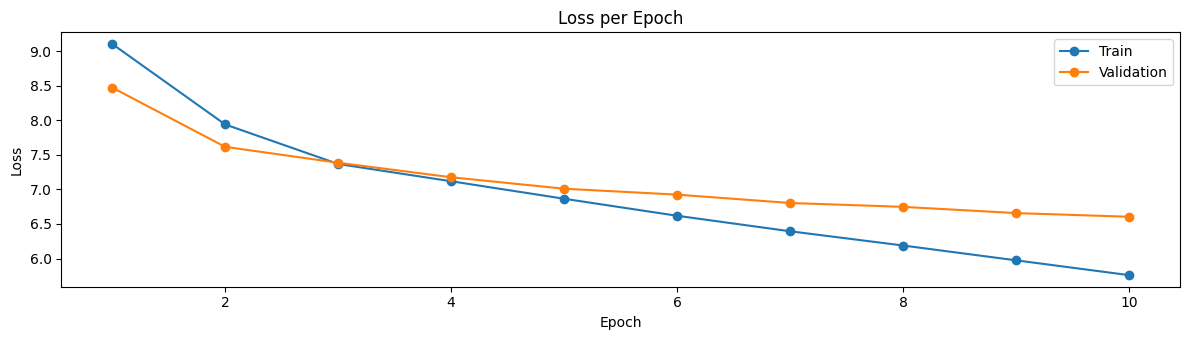

Final train loss: 5.7603
Final validation loss: 6.6045

Analysis:
- Training loss trend slope: -0.3160 (more negative ⇒ faster convergence)
- Validation loss trend slope: -0.1691
- Final generalization gap (val - train): 0.8442
- Observation: Both training and validation losses are decreasing — model still improving. You can continue training or lower the learning rate as improvements slow.


In [ ]:
# TODO: Create comprehensive training visualization
# TODO: Plot training and validation losses
# TODO: Display final training statistics

import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

# Try to use in-memory history; otherwise load from the JSON we saved during training
if 'history' not in globals() or not isinstance(history, dict) or not history.get('epoch'):
    with open(Path('./checkpoints/training_history.json'), 'r') as f:
        history = json.load(f)

epochs = history["epoch"]
train_losses = history["train_loss"]
val_losses = history["val_loss"]

# Plot losses
plt.figure(figsize=(12, 3.5))
plt.plot(epochs, train_losses, marker='o', label='Train')
plt.plot(epochs, val_losses, marker='o', label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss per Epoch')
plt.legend()
plt.grid(False)
plt.tight_layout()
plt.show()

# Final stats
final_train = float(train_losses[-1])
final_val = float(val_losses[-1])
print(f"Final train loss: {final_train:.4f}")
print(f"Final validation loss: {final_val:.4f}")

# Simple, concise analysis (convergence / overfitting signal)
def _trend(x):
    # negative slope means decreasing loss
    if len(x) < 2:
        return 0.0
    xs = np.arange(len(x))
    m = np.polyfit(xs, x, 1)[0]
    return m

train_slope = _trend(train_losses)
val_slope = _trend(val_losses)
gap = final_val - final_train

print("\nAnalysis:")
print(f"- Training loss trend slope: {train_slope:.4f} (more negative ⇒ faster convergence)")
print(f"- Validation loss trend slope: {val_slope:.4f}")
print(f"- Final generalization gap (val - train): {gap:.4f}")

if gap > 0.3 and val_slope > -0.01:
    print("- Observation: Validation loss is higher than training and not decreasing much — mild overfitting. "
          "Consider stronger regularization (dropout/label smoothing), earlier stopping, or data augmentation.")
elif val_slope < -0.01:
    print("- Observation: Both training and validation losses are decreasing — model still improving. "
          "You can continue training or lower the learning rate as improvements slow.")
else:
    print("- Observation: Loss curves are largely flat — consider reducing learning rate, increasing batch size, "
          "or revisiting tokenizer/vocabulary limits.")


### 📊 Evaluation Criteria

Your assignment will be evaluated based on:

1. **Architecture Implementation (50%)**
   - Correct Positional Encoding implementation
   - Proper Transformer Encoder with multi-head attention
   - Correct Transformer Decoder with causal masking
   - Appropriate text generation function
   - Proper handling of padding and special tokens

2. **Training Implementation (30%)**
   - Correct dataset preparation and batching
   - Proper loss calculation with label smoothing
   - Effective training loop with gradient clipping
   - Learning rate scheduling implementation
   - Model convergence and validation

3. **Code Quality and Analysis (20%)**
   - Clean, well-documented code with proper structure
   - Correct ROUGE evaluation
